# Epithelial reintegration, manual CNV review and clustering


## Analysis audit and decisions

This notebook is a pre-step for the Gavish meta-programme analysis. The workflow has one explicit malignancy call and keeps diagnostic quantities separate from that call.

- Each epithelial sample is deterministically capped at 5,000 cells before normalisation, inferCNV, scVI and clustering. The selected cell IDs and before/after counts are exported.
- The inferCNV burden score is diagnostic only. It is not used as the primary malignancy classifier because burden can be high without a visually coherent chromosome-spanning pattern.
- A chromosome-wide `cnv_signature_score` is calculated relative to a visually selected malignant anchor profile. It is used to order cells and clusters in review heatmaps, not as the final hard label in this version.
- Leiden resolution 2 is used specifically for the CNV malignancy review. The primary epithelial clustering retained for downstream Gavish analysis remains the predeclared resolution 1.2 (`epi_leiden`).
- The final operational call defines all `condition == "N"` cells, all cells in normal-dominated resolution-2 clusters, and the manually reviewed non-malignant resolution-2 clusters as non-malignant. All remaining cells are labelled malignant. This is an analysis-level, review-based definition and is not an independent pathological truth label.
- The checkpoint after scVI, neighbours, UMAP and all Leiden resolutions is retained. The inferCNV matrix is reloaded separately after a resume to avoid duplicating it in the checkpoint.
- Cell-level condition fractions are descriptive. Biological comparisons should use sample/donor-level summaries rather than treating cells as independent biological replicates.
- The inferCNV gene exclusions, reference strategy and signature-template choices are documented sensitivity decisions and should be reported as such.


## Setup

In [1]:
import os
os.environ["NUMBA_THREADING_LAYER"] = "workqueue"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"#4 Nina 2 avoid kernel crashing

In [2]:
import gc
import re
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import scanpy as sc
import anndata as ad
import infercnvpy as cnv
import scvi

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.gridspec import GridSpec

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
os.environ["RPY2_CFFI_MODE"] = "ABI"

import rpy2.robjects as ro
import rpy2.rinterface_lib.callbacks as rcb
import logging

In [4]:
# Reproducibility and analysis configuration
RANDOM_SEED = 0
MAX_CELLS_PER_SAMPLE = 5000
HEATMAP_MAX_CELLS = 5000
HEATMAP_CELLS_PER_GROUP = HEATMAP_MAX_CELLS // 2
PRIMARY_LEIDEN_RESOLUTION = 1.2
LEIDEN_RESOLUTIONS = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 2.0]
SCVI_EARLY_STOPPING_MIN_DELTA = 0.1

np.random.seed(RANDOM_SEED)
scvi.settings.seed = RANDOM_SEED
scvi.settings.num_workers = 4

sc.settings.verbosity = 2
rcb.logger.setLevel(logging.ERROR)


Seed set to 0


In [5]:
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")

plt.rcParams.update({
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 16,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
})

In [6]:

target_genes = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]

In [7]:
# paths; set CAP_PROJECT to run this outside the author's machine
#project  = Path(os.environ.get("CAP_PROJECT","~/Downloads/1105_Project_Nowotny")).expanduser()#4 Helena
project  = Path(os.environ.get("CAP_PROJECT", "/Volumes/TOSHIBA EXT/IdeaProjects/Nowotny")).expanduser()#4 Nina
data_dir = project / "Data"
fig_dir = project / "Figures"
df_dir = project / "Dataframe_Saves"
save_dir = project / "Adata_Saves"
model_dir = project / "scvi_epithelial_model"
notebook_dir = project / "Input_Dataframes"#4 Nina

for d in [fig_dir, df_dir, save_dir, model_dir]:
    d.mkdir(parents=True, exist_ok=True)

# keep every scanpy figure in the same place as the plt.savefig output
sc.settings.figdir = fig_dir

#gavish_file = notebook_dir / "Gavish_cell_state_signature.xlsx"#4 Helena
gavish_file = data_dir / "Gavish_cell_state_signature.xlsx"#4 Nina
gencode_file = data_dir / "gencode.v50.annotation.gtf"
#gencode_file = data_dir / "gencode.v50.annotation.gtf.gz"#4 Helena

for f in [gavish_file, gencode_file]:
    assert f.exists(), f

# show paths relative to the project root, so no absolute path is ever printed
def rel(path):
    return Path(path).relative_to(project)

## Load the epithelial compartment

In [ ]:
# Read the object in backed mode first. This keeps the full atlas matrix
# on disk while the <=5,000-cell-per-sample selection is calculated from obs.
epi_path = save_dir / "epithelial.h5ad"
epi_backed = sc.read_h5ad(epi_path, backed="r")

# Remove atlas-only objects while still backed, before any selected cells are
# materialised. In particular, never slice a large pairwise graph just to
# clear it afterwards.
for key in ["X_scVI", "X_umap", "X_pca"]:
    epi_backed.obsm.pop(key, None)
epi_backed.obsp.clear()
for key in ["neighbors", "umap", "rank_genes_groups", "hvg", "scVI_leiden", "scVI_leiden_colors"]:
    epi_backed.uns.pop(key, None)
if "scVI_leiden" in epi_backed.obs.columns:
    epi_backed.obs.drop(columns=["scVI_leiden"], inplace=True)
epi_backed.var.drop(
    columns=[c for c in [
        "highly_variable", "highly_variable_rank", "highly_variable_nbatches",
        "highly_variable_atlas", "highly_variable_rank_atlas",
        "highly_variable_nbatches_atlas",
    ] if c in epi_backed.var.columns],
    inplace=True,
)

print(epi_backed)
print(epi_backed.obs["condition"].value_counts().to_string())

n_cells_before_cap = epi_backed.n_obs
n_genes_loaded = epi_backed.n_vars
sample_sizes_before_cap = epi_backed.obs["sample"].value_counts().sort_index()

def _stratified_sample_indices(frame, n, strata_key=None, seed=RANDOM_SEED):
    """Return exactly n row IDs, preserving strata approximately when possible."""
    if n >= len(frame):
        return frame.index.to_numpy()
    rng = np.random.default_rng(seed)
    if strata_key is None or strata_key not in frame.columns:
        return rng.choice(frame.index.to_numpy(), size=n, replace=False)

    strata = frame[strata_key].astype(str).fillna("NA")
    counts = strata.value_counts(sort=False)
    raw = counts / counts.sum() * n
    allocation = np.floor(raw).astype(int).clip(upper=counts)

    # Largest-remainder allocation gives the requested total without
    # preferentially discarding small annotated strata.
    while int(allocation.sum()) < n:
        candidates = allocation[allocation < counts].index
        if len(candidates) == 0:
            break
        remainder = (raw - allocation).loc[candidates]
        chosen = remainder.sort_values(ascending=False, kind="mergesort").index[0]
        allocation.loc[chosen] += 1

    selected = []
    for label, n_label in allocation.items():
        if n_label:
            ids = frame.index[strata.eq(label)]
            selected.extend(rng.choice(ids.to_numpy(), size=int(n_label), replace=False).tolist())
    return np.asarray(selected)

selected_ids = []
for sample, group in epi_backed.obs.groupby("sample", observed=True, sort=True):
    strata_key = "cl_annotation" if "cl_annotation" in group.columns else None
    selected_ids.extend(_stratified_sample_indices(
        group, min(MAX_CELLS_PER_SAMPLE, len(group)), strata_key=strata_key,
        seed=RANDOM_SEED + int(hashlib.sha256(str(sample).encode()).hexdigest()[:8], 16) % 100000,
    ).tolist())

selected_id_set = set(selected_ids)
selected_mask = epi_backed.obs_names.isin(selected_id_set)

# Materialise only the capped cells. The full object is still backed and is
# closed before downstream work, avoiding a full-object-plus-copy peak.
epi = epi_backed[selected_mask].to_memory()
epi_backed.file.close()
del epi_backed
gc.collect()

assert epi.n_obs == len(selected_id_set)
assert int(epi.obs.groupby("sample", observed=True).size().max()) <= MAX_CELLS_PER_SAMPLE

sample_cap_summary = (
    sample_sizes_before_cap.rename("n_cells_before")
    .to_frame().join(epi.obs["sample"].value_counts().rename("n_cells_after"), how="left")
    .fillna(0).astype(int)
)
sample_cap_summary["n_cells_removed"] = sample_cap_summary["n_cells_before"] - sample_cap_summary["n_cells_after"]
sample_cap_summary.index.name = "sample"
sample_cap_summary.to_csv(df_dir / "epithelial_sample_cap_summary.csv")
pd.Series(epi.obs_names.astype(str), name="cell_id").to_csv(
    df_dir / "epithelial_sample_cap_selected_cell_ids.csv", index=False
)

n_cells_loaded = epi.n_obs
print(f"cells before cap: {n_cells_before_cap:,}")
print(f"cells after cap:  {n_cells_loaded:,}")
print(f"maximum cells per sample: {sample_cap_summary['n_cells_after'].max():,}")


In [ ]:
# The atlas representation was already removed while the source was backed.
# Repeat the cleanup defensively after materialisation; no renamed atlas copies
# are retained in the epithelial object.
for key in ["X_scVI", "X_umap", "X_pca"]:
    epi.obsm.pop(key, None)

for key in ["neighbors", "umap", "rank_genes_groups", "hvg", "scVI_leiden", "scVI_leiden_colors"]:
    epi.uns.pop(key, None)

if "scVI_leiden" in epi.obs.columns:
    epi.obs.drop(columns=["scVI_leiden"], inplace=True)

# These atlas-level flags are not needed for epithelial HVG selection.
epi.var.drop(
    columns=[
        c for c in [
            "highly_variable_atlas", "highly_variable_rank_atlas",
            "highly_variable_nbatches_atlas",
        ] if c in epi.var.columns
    ],
    inplace=True,
)

# Pairwise graphs are large and are rebuilt later from the epithelial-only
# scVI representation.
epi.obsp.clear()
gc.collect()

print("retained obsm keys:", list(epi.obsm.keys()))


In [ ]:
# counts must be untouched integers; every downstream threshold depends on it
assert "counts" in epi.layers

counts = epi.layers["counts"]

assert sp.issparse(counts), "Expected layers['counts'] to remain sparse"
assert np.isfinite(counts.data).all()
assert np.equal(counts.data, np.floor(counts.data)).all(), (
    "counts layer is not integer"
)

# Positive-cell counts using sparse operations only.
baseline_positive = {
    gene: (
        int(counts[:, epi.var_names.get_loc(gene)].getnnz())
        if gene in epi.var_names else 0
    )
    for gene in target_genes
}

print(baseline_positive)

## Gene filtering and normalisation

In [ ]:
# Gene filtering is applied after the sample cap; raw counts stay in layers["counts"].
n_genes_loaded = epi.n_vars
epi.X = epi.layers["counts"].copy()

sc.pp.filter_genes(epi, min_cells=3)

n_genes_removed = n_genes_loaded - epi.n_vars

print(f"cells after sample cap: {n_cells_loaded:,}")
print(f"genes loaded:          {n_genes_loaded:,}")
print(f"filtered: {n_genes_removed:,} genes in fewer than {3} epithelial cells")
print(f"master:   {epi.n_obs:,} cells x {epi.n_vars:,} genes")


In [ ]:
# X holds log-normalised expression from here on; raw counts stay in layers
sc.pp.normalize_total(epi, target_sum=1e4)
sc.pp.log1p(epi)

epi.layers["lognorm"] = epi.X.copy()

# 002 stored lognorm twice under two names; keep one
epi.layers.pop("log1p", None)

print(list(epi.layers.keys()))

In [ ]:
# the master shape that must survive inferCNV, scVI and clustering unchanged
n_cells_start = epi.n_obs
n_genes_start = epi.n_vars

assert n_cells_start == n_cells_loaded
assert n_genes_start == n_genes_loaded - n_genes_removed

## Highly variable genes

Binomial deviance (`scry`) computed per sample and aggregated by the maximum
across samples, so that a gene deviant in a single condition is retained.
Mitochondrial, ribosomal and haemoglobin genes are excluded before ranking.
Cell-cycle genes are deliberately **not** excluded here: proliferation is a
malignant cell state of interest.

In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R
suppressPackageStartupMessages({
    library(Matrix)
    library(SingleCellExperiment)
    library(scry)
})

In [ ]:
def scipy_to_dgc(matrix):
    # transfer a scipy sparse matrix to R as a dgCMatrix
    matrix = sp.csc_matrix(matrix)
    return ro.r["new"](
        "dgCMatrix",
        i=ro.IntVector(matrix.indices),
        p=ro.IntVector(matrix.indptr),
        x=ro.FloatVector(matrix.data),
        Dim=ro.IntVector(matrix.shape),
    )

In [ ]:
samples = epi.obs["sample"].astype(str).unique().tolist()
deviance = pd.DataFrame(index=epi.var_names, columns=samples, dtype=float)

for sample in samples:
    sub = epi[epi.obs["sample"].astype(str) == sample]
    ro.globalenv["raw_counts"] = scipy_to_dgc(sub.layers["counts"].T)
    ro.globalenv["gene_names"] = ro.StrVector(sub.var_names.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(sub.obs_names.tolist())

    ro.r('''
        rownames(raw_counts) <- gene_names
        colnames(raw_counts) <- cell_names
        sce <- SingleCellExperiment(assays = list(counts = raw_counts))
        sce <- devianceFeatureSelection(sce)
        binomial_deviance <- rowData(sce)$binomial_deviance
    ''')

    deviance[sample] = np.asarray(ro.r["binomial_deviance"])
    ro.r("rm(raw_counts, sce, binomial_deviance); gc()")
    print(f"{sample}: {sub.n_obs:,} cells")

epi.var["binomial_deviance"] = deviance.max(axis=1)
assert epi.var["binomial_deviance"].notna().all()

In [ ]:
# genes excluded from ranking, but not from the object
for col in ["mt", "ribo", "hb"]:
    assert col in epi.var.columns, col
exclude = epi.var[["mt", "ribo", "hb"]].any(axis=1)
print(f"excluded from ranking: {int(exclude.sum()):,}")

In [ ]:
ranked = (
    epi.var.loc[~exclude, "binomial_deviance"]
    .sort_values(ascending=False)
    .index
)

deviant_genes = ranked[:4000]
print(f"deviance-ranked genes: {len(deviant_genes):,}")

In [ ]:
# protected genes: the four antigen targets plus every Gavish cancer meta-programme gene, retained irrespective of deviance rank
gavish_sheet = pd.read_excel(gavish_file, sheet_name="Cancer MPs")
gavish_sheet.columns = (
    gavish_sheet.columns.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
)

gavish_states = {}
mp_id_to_name = {}

for state in gavish_sheet.columns:
    genes = gavish_sheet[state].dropna().astype(str).str.strip()
    genes = genes[genes.ne("")].unique().tolist()
    mp_id = re.match(r"^(MP\d+)\b", state).group(1)
    gavish_states[state] = genes
    mp_id_to_name[mp_id] = state

assert len(gavish_states) == 41
gavish_genes = sorted({g for genes in gavish_states.values() for g in genes})

print(f"meta-programmes: {len(gavish_states)}")
print(f"unique Gavish genes: {len(gavish_genes):,}")

In [ ]:
protected = sorted(set(target_genes) | set(gavish_genes))
protected_present = [g for g in protected if g in epi.var_names]

print(f"protected genes present: {len(protected_present):,} / {len(protected):,}")

In [ ]:
# two feature sets are recorded:   highly_variable_deviance : the 4,000 deviance-ranked genes, unbiased   highly_variable          : those plus the protected genes, used by scVI
# because the Methods require them ALRA in 003c and the robustness appendix below both use the deviance-only set, so neither depends on the protected-gene decision.
epi.var["highly_variable_deviance"] = epi.var_names.isin(deviant_genes)
epi.var["highly_variable"] = (epi.var["highly_variable_deviance"] | epi.var_names.isin(protected_present))

n_hvg = int(epi.var["highly_variable"].sum())
n_hvg_deviance = int(epi.var["highly_variable_deviance"].sum())
n_protected_added = n_hvg - n_hvg_deviance

print(f"deviance-ranked genes:      {n_hvg_deviance:,}")
print(f"added by the protected list: {n_protected_added:,}")
print(f"scVI feature set:           {n_hvg:,} "
      f"({100 * n_protected_added / n_hvg:.1f}% protected)")

for gene in target_genes:
    assert epi.var.loc[gene, "highly_variable"], gene

pd.Series(epi.var_names[epi.var["highly_variable"]]).to_csv(df_dir / "epithelial_hvg_genes.csv", index=False, header=False)

## inferCNV



Run on a copy of the object, so that the gene filtering required by inferCNV
does not shrink the master object. Coordinates come from GENCODE v50 joined on
Ensembl gene ID; symbol matching resolves far fewer genes.

In [ ]:
# inferCNV needs log-normalised expression, the sample annotation and the gene coordinates. A full epi.copy() would also carry the counts layer and double peak memory for no benefit, so the working object is built slim.
cnv_adata = ad.AnnData(
    X=epi.layers["lognorm"].copy(),
    obs=epi.obs.copy(),
    var=epi.var.copy(),
)

print(f"inferCNV working object: {cnv_adata.n_obs:,} cells x {cnv_adata.n_vars:,} genes")

In [ ]:
gtf = pd.read_csv(gencode_file,
    sep="\t", comment="#", header=None,
    names=["chromosome", "source", "feature", "start", "end",
           "score", "strand", "frame", "attribute"],
)

In [ ]:

gencode = gtf[gtf["feature"] == "gene"].copy()

In [ ]:

gencode["ensembl"] = (
    gencode["attribute"].str.extract(r'gene_id "([^"]+)"')[0].str.split(".").str[0]
)

In [ ]:

gencode["gene_type"] = gencode["attribute"].str.extract(r'gene_type "([^"]+)"')[0]

In [ ]:

gencode = gencode.drop_duplicates("ensembl").set_index("ensembl")

In [ ]:

len(gencode)

In [ ]:

del gtf
gc.collect()

In [ ]:
# join on stable Ensembl identifiers taken from the dataset's own annotation
ensembl = cnv_adata.var["gene_id"].astype(str).str.split(".").str[0]

In [ ]:

cnv_adata.var["chromosome"] = ensembl.map(gencode["chromosome"]).values
cnv_adata.var["start"] = ensembl.map(gencode["start"]).values
cnv_adata.var["end"] = ensembl.map(gencode["end"]).values
cnv_adata.var["gene_type"] = ensembl.map(gencode["gene_type"]).values

resolved = cnv_adata.var["chromosome"].notna()

In [ ]:
# free the large intermediates; nothing below uses them
del gencode
gc.collect()

In [ ]:

resolved.sum(), cnv_adata.n_vars

In [ ]:

cnv_adata.var.loc[~resolved, ["gene_id"]].to_csv(df_dir / "infercnv_unresolved_genes.csv")

In [ ]:
# protein-coding autosomal genes only

In [ ]:
autosomes = [f"chr{i}" for i in range(1, 23)]

keep = (
    cnv_adata.var["chromosome"].isin(autosomes)
    & cnv_adata.var["gene_type"].eq("protein_coding")
)

In [ ]:

cnv_adata = cnv_adata[:, keep].copy()

In [ ]:

cnv_adata.n_vars

In [ ]:
# gene families whose variation is not driven by copy number
problematic = (
    cnv_adata.var_names.str.startswith(
        ("MT-", "RPS", "RPL", "HLA-", "IGH", "IGK", "IGL", "KRT", "SPRR", "S100A")
    )
    | cnv_adata.var_names.isin(["MALAT1", "NEAT1"])
)

In [ ]:

problematic.sum()

In [ ]:

cnv_adata = cnv_adata[:, ~problematic].copy()

In [ ]:

sc.pp.filter_genes(cnv_adata, min_cells=100)

In [ ]:

cnv_adata.n_vars

In [ ]:
# genomic ordering
cnv_adata.var["chromosome"] = cnv_adata.var["chromosome"].astype(str)
cnv_adata.var["chr_num"] = cnv_adata.var["chromosome"].str.replace("chr", "", regex=False).astype(int)

order = cnv_adata.var.sort_values(["chr_num", "start"]).index
cnv_adata = cnv_adata[:, order].copy()

assert cnv_adata.var_names.is_unique
assert (np.diff(cnv_adata.var["chr_num"].to_numpy()) >= 0).all()

In [ ]:
# normal epithelium provides the diploid reference
reference = cnv_adata[cnv_adata.obs["condition"] == "N"].copy()

print(f"reference cells: {reference.n_obs:,} from {reference.obs['sample'].nunique()} samples")

In [ ]:
cnv_adata.obs["cnv_score"] = np.nan
cnv_adata.obs["cnv_signal"] = np.nan

x_cnv_full = None
failures = []

cnv_samples = cnv_adata.obs["sample"].astype(str).unique().tolist()

In [ ]:
len(cnv_samples)

In [ ]:
for sample in cnv_samples:

    print(f"\n{sample}")

    target = refs = combined = None

    try:
        target = cnv_adata[cnv_adata.obs["sample"].astype(str) == sample].copy()
        condition = str(target.obs["condition"].iloc[0])

        # a normal sample is never its own reference
        if condition == "N":
            refs = reference[reference.obs["sample"].astype(str) != sample].copy()
        else:
            refs = reference.copy()

        assert refs.n_obs > 0

        refs.obs["cnv_reference"] = "reference"
        target.obs["cnv_reference"] = "query"

        combined = sc.concat([refs, target], join="inner", merge="same")

        print(f"  {condition}: {target.n_obs:,} query, {refs.n_obs:,} reference")

        # X holds log-normalised expression, so no layer is passed
        cnv.tl.infercnv(
            combined,
            reference_key="cnv_reference",
            reference_cat=["reference"],
            window_size=100,
            step=10,
            dynamic_threshold=0.5,
            exclude_chromosomes=("chrX", "chrY"),
            n_jobs=1,
        )

        x_cnv = combined.obsm["X_cnv"]
        x_cnv = x_cnv.toarray() if sp.issparse(x_cnv) else np.asarray(x_cnv)
        x_cnv = x_cnv.astype(np.float32)

        query = combined.obs["cnv_reference"].eq("query").to_numpy()
        query_names = combined.obs_names[query]
        x_query = x_cnv[query]

        # map each inferCNV window to its chromosome
        chr_pos = sorted(combined.uns["cnv"]["chr_pos"].items(), key=lambda kv: kv[1])
        n_windows = x_query.shape[1]

        chr_labels = np.empty(n_windows, dtype=object)

        for i, (chrom, start) in enumerate(chr_pos):
            end = chr_pos[i + 1][1] if i + 1 < len(chr_pos) else n_windows
            chr_labels[start:end] = chrom

        # root-mean-square burden per chromosome, weighted by window count, so that long chromosomes do not dominate the cell-level score
        chrom_scores = []
        chrom_weights = []

        for chrom in pd.unique(chr_labels):
            idx = np.flatnonzero(chr_labels == chrom)
            chrom_scores.append(np.sqrt(np.mean(x_query[:, idx] ** 2, axis=1)))
            chrom_weights.append(len(idx))

        chrom_scores = np.column_stack(chrom_scores)
        chrom_weights = np.asarray(chrom_weights, dtype=float)
        chrom_weights /= chrom_weights.sum()

        cnv_score = np.average(chrom_scores, axis=1, weights=chrom_weights)
        cnv_signal = np.max(np.abs(x_query), axis=1)

        cnv_adata.obs.loc[query_names, "cnv_score"] = cnv_score
        cnv_adata.obs.loc[query_names, "cnv_signal"] = cnv_signal

        if x_cnv_full is None:
            x_cnv_full = np.full((cnv_adata.n_obs, n_windows), np.nan, dtype=np.float32)

        if "cnv" not in cnv_adata.uns:
            cnv_adata.uns["cnv"] = dict(combined.uns["cnv"])

        x_cnv_full[cnv_adata.obs_names.get_indexer(query_names)] = x_query

        print(f"  median burden {np.median(cnv_score):.4f}")

    except Exception as error:
        print(f"  failed: {error}")
        failures.append({"sample": sample, "error": str(error)})

    finally:
        del target, refs, combined
        gc.collect()

In [ ]:
# a failed sample would leave cnv_score NaN, fall below the threshold and be silently called non-malignant, so stop rather than continue
failures = pd.DataFrame(failures)
if not failures.empty:
    failures.to_csv(df_dir / "infercnv_failed_samples.csv", index=False)
    raise RuntimeError(f"inferCNV failed for {len(failures)} sample(s)")
assert cnv_adata.obs[["cnv_score", "cnv_signal"]].notna().all().all()
print("all samples completed")

In [ ]:
# the burden should not simply track sequencing depth
cnv_score_total_counts_r = np.corrcoef(cnv_adata.obs["cnv_score"], cnv_adata.obs["total_counts"])[0, 1]
print(f"cnv_score vs total_counts: r = {cnv_score_total_counts_r:.3f}")

In [ ]:
cnv_adata.obs.groupby("condition", observed=True)["cnv_score"].describe().round(4)

## CNV Burden

In [ ]:
# Diagnostic CNV screening threshold only. This is not the primary malignancy call.
# Scores for normal samples were generated leave-one-normal-sample-out, so the
# normal distribution is not contaminated by a sample's own reference cells.
# Nevertheless, a normal 95th percentile is a screening rule, not a validated
# biological malignant cutoff.
normal_scores = cnv_adata.obs.loc[cnv_adata.obs["condition"] == "N", "cnv_score"].dropna()
cnv_screen_quantile = 1.0
cnv_screen_threshold = float(normal_scores.quantile(cnv_screen_quantile))

cnv_adata.obs["cnv_high_screen"] = cnv_adata.obs["cnv_score"].gt(cnv_screen_threshold)
print(f"diagnostic normal quantile: q={cnv_screen_quantile:.2f}")
print(f"diagnostic threshold: {cnv_screen_threshold:.4f}")
print(pd.crosstab(cnv_adata.obs["condition"], cnv_adata.obs["cnv_high_screen"], margins=True))


In [ ]:
# Sensitivity of the diagnostic screen to the normal-reference quantile.
# These values are not used to choose the primary manual call.
rows = []
for quantile in [0.90, 0.95, 0.99]:
    threshold = float(normal_scores.quantile(quantile))
    called = cnv_adata.obs["cnv_score"].gt(threshold)
    for condition in ["N", "ER+", "HER2+", "TN"]:
        mask = cnv_adata.obs["condition"].eq(condition)
        rows.append({
            "quantile": quantile, "threshold": threshold, "condition": condition,
            "n_cells": int(mask.sum()), "n_above_screen": int(called[mask].sum()),
            "fraction_above_screen": float(called[mask].mean()),
        })
threshold_sensitivity = pd.DataFrame(rows)
print(threshold_sensitivity.round(4).to_string(index=False))
threshold_sensitivity.to_csv(df_dir / "infercnv_screen_threshold_sensitivity_diagnostic.csv", index=False)


In [ ]:
sample_malignancy = (
    cnv_adata.obs
    .groupby(["sample", "condition"], observed=True)
    .agg(n_cells=("cnv_high_screen", "size"),
         n_above_screen=("cnv_high_screen", "sum"),
         median_cnv=("cnv_score", "median"))
    .reset_index()
)
sample_malignancy["fraction_above_screen"] = sample_malignancy["n_above_screen"] / sample_malignancy["n_cells"]
sample_malignancy.sort_values(["condition", "fraction_above_screen"]).round(3)


In [ ]:
sample_malignancy.to_csv(df_dir / "infercnv_cnv_screen_by_sample.csv", index=False)


The sample-level table above is a diagnostic screen. It is not evidence that every cell above the screen is malignant.


In [ ]:
display(sample_malignancy)


### Visualising CNV Burden

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=cnv_adata.obs, x="cnv_score", hue="condition", bins=100,
    stat="density", common_norm=False, element="step", ax=ax,
)
ax.axvline(cnv_screen_threshold, linestyle="--", linewidth=1.5, color="black",
           label=f"normal q{cnv_screen_quantile:.2f} diagnostic screen")
ax.set_xlabel("inferCNV burden (weighted chromosome-level RMS)")
ax.set_ylabel("density")
ax.legend(frameon=False)
sns.despine()
plt.savefig(fig_dir / "infercnv_diagnostic_screen.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(
    data=sample_malignancy, x="sample", y="fraction_above_screen",
    hue="condition", dodge=False, ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("fraction above diagnostic CNV screen")
ax.tick_params(axis="x", rotation=90, labelsize=7)
sns.despine()
plt.savefig(fig_dir / "infercnv_diagnostic_screen_fraction_by_sample.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
assert epi.obs_names.equals(cnv_adata.obs_names)


In [ ]:
for col in ["cnv_score", "cnv_signal", "cnv_high_screen"]:
    epi.obs[col] = cnv_adata.obs[col].reindex(epi.obs_names)


In [ ]:
epi.obs["cnv_high_screen"] = epi.obs["cnv_high_screen"].astype(bool)


In [ ]:
# The primary call is deliberately initialised as pending. It is populated
# by the manual-review cell after the capped genomic heatmap is inspected.
epi.obs["malignant"] = pd.Series(False, index=epi.obs_names, dtype=bool)
epi.obs["malignancy_review_pending"] = True
epi.obs["malignancy_status"] = "Review_pending"


In [ ]:
epi.uns["malignancy_call"] = {
    "primary_call": "pending_resolution_2_cluster_review",
    "status": "pending_visual_review",
    "diagnostic_screen": "normal epithelial q0.95, leave-one-normal-sample-out scores",
    "diagnostic_screen_threshold": float(cnv_screen_threshold),
    "reference": "normal epithelial cells, leave-one-sample-out for normal samples",
    "gene_annotation": "GENCODE v50, joined on Ensembl gene id",
    "expression_layer": "log-normalised expression",
    "window_size": 100,
    "step": 10,
    "dynamic_threshold": 0.5,
    "cnv_score": "chromosome-level RMS burden, weighted by window count",
    "cnv_score_vs_total_counts_r": float(cnv_score_total_counts_r),
    "cnv_score_used_for_primary_call": False,
    "cnv_signature_used_for_ordering": True,
    "condition_label_used_for_final_exclusion": True,
    "correlation_rescue_used": False,
    "patient_private_cluster_rescue_used": False,
}

print("Primary malignancy call is pending resolution-2 cluster review.")


In [ ]:
print("Cells above diagnostic CNV screen:", int(epi.obs["cnv_high_screen"].sum()))


In [ ]:
cnv_adata.obsm["X_cnv"] = x_cnv_full
cnv_adata.write_h5ad(save_dir / "epithelial_infercnv.h5ad", compression="gzip")


In [ ]:

del cnv_adata, reference, x_cnv_full
gc.collect()

## SCVI

In [ ]:
epi_scvi = epi[:, epi.var["highly_variable"]].copy()

In [ ]:

assert epi_scvi.n_obs == epi.n_obs
assert epi_scvi.n_vars == n_hvg

In [ ]:
epi_scvi.shape

In [ ]:
# sample (library) identity is the batch covariate
scvi.model.SCVI.setup_anndata(epi_scvi, layer="counts", batch_key="sample")

In [ ]:

model = scvi.model.SCVI(epi_scvi,n_latent=20,n_layers=2,gene_likelihood='nb',)

In [ ]:
# free the large intermediates; nothing below uses them
del epi_scvi
gc.collect()

In [ ]:
model

In [ ]:
# A small, explicit minimum ELBO improvement avoids stopping on a single
# large-scale numerical fluctuation while remaining less arbitrary than 1.0.
model.train(
    max_epochs=400, accelerator="mps", batch_size=1024, early_stopping=True, early_stopping_patience=20,
    early_stopping_min_delta=SCVI_EARLY_STOPPING_MIN_DELTA,)

In [ ]:
n_epochs = model.history["elbo_train"].shape[0]

In [ ]:
n_epochs

In [ ]:
model.save(str(model_dir), overwrite=True)
model.history["elbo_train"].to_csv(df_dir / "scvi_epithelial_history.csv")

In [ ]:

latent = model.get_latent_representation()

In [ ]:

assert latent.shape == (epi.n_obs, 20)
assert np.isfinite(latent).all()

In [ ]:

epi.obsm["X_scVI"] = latent

In [ ]:

latent.shape

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

model.history["elbo_train"].plot(ax=ax, legend=False)

ax.set_xlabel("epoch")
ax.set_ylabel("training ELBO")
sns.despine()

plt.savefig(fig_dir / "scvi_epithelial_elbo.png", dpi=300, bbox_inches="tight")
plt.show()

## Neighbours, UMAP and Leiden clustering

In [ ]:
sc.pp.neighbors(epi, use_rep="X_scVI", n_neighbors=30, random_state=0)

sc.tl.umap(epi, random_state=0)

In [ ]:
from sklearn.metrics import adjusted_rand_score

In [ ]:
from sklearn.metrics import adjusted_rand_score

leiden_resolutions = list(LEIDEN_RESOLUTIONS)
primary_resolution = float(PRIMARY_LEIDEN_RESOLUTION)
assert primary_resolution in leiden_resolutions


In [ ]:
for resolution in leiden_resolutions:
    key = f"leiden_r{resolution:g}"
    sc.tl.leiden(
        epi, resolution=resolution, key_added=key,
        flavor="igraph", n_iterations=2, directed=False, random_state=RANDOM_SEED,
    )
    print(f"resolution {resolution:g}: {epi.obs[key].nunique()} clusters")


In [ ]:
primary_key = f"leiden_r{primary_resolution:g}"
resolution_rows = []
for resolution in leiden_resolutions:
    key = f"leiden_r{resolution:g}"
    sizes = epi.obs[key].value_counts()
    resolution_rows.append({
        "resolution": float(resolution),
        "n_clusters": int(sizes.size),
        "min_cluster_size": int(sizes.min()),
        "median_cluster_size": float(sizes.median()),
        "max_cluster_size": int(sizes.max()),
        "n_singleton_clusters": int((sizes == 1).sum()),
        "ARI_vs_primary_1.2": float(adjusted_rand_score(epi.obs[primary_key], epi.obs[key])),
    })

leiden_resolution_table = pd.DataFrame(resolution_rows).sort_values("resolution")
print(leiden_resolution_table.round(3).to_string(index=False))
leiden_resolution_table.to_csv(df_dir / "leiden_resolution_cluster_count_table.csv", index=False)


In [ ]:
# Resolution 1.2 is the predeclared primary clustering used downstream in 003b.
epi.obs["epi_leiden"] = epi.obs[primary_key].copy()
epi.uns["leiden_primary_resolution"] = primary_resolution
epi.uns["leiden_resolution_table"] = leiden_resolution_table.to_dict(orient="records")


In [ ]:
epi.obs["epi_leiden"].value_counts().sort_index()


### Small Checkpoint

In [ ]:
# ============================================
# DIAGNOSTIC — find non-writable obs/var/uns entries
# ============================================
def _check_obs_var(df, label):
    for col in df.columns:
        if df[col].dtype == object:
            types_seen = df[col].map(type).unique()
            if len(types_seen) > 1:
                print(f"[{label}] '{col}' has mixed types: {types_seen}")


_check_obs_var(epi.obs, "obs")
_check_obs_var(epi.var, "var")


def _check_uns(d, prefix="uns"):
    for k, v in d.items():
        path = f"{prefix}['{k}']"
        if isinstance(v, dict):
            _check_uns(v, path)
        elif isinstance(v, list):
            if any(isinstance(x, dict) for x in v):
                print(f"{path} is a list of dicts — not h5ad-writable as-is")
            elif len(v) and not all(isinstance(x, type(v[0])) for x in v):
                print(f"{path} is a list with mixed element types")
        elif not isinstance(v, (str, int, float, bool, np.ndarray, type(None))):
            print(f"{path} has unsupported type: {type(v)}")


_check_uns(epi.uns)

In [ ]:
# ============================================
# CHECKPOINT — save epi after neighbours/UMAP/Leiden
# ============================================
# Protects against recomputation of scVI latent space, neighbours graph,
# and all Leiden resolutions after a kernel crash.
# The inferCNV matrix itself is NOT duplicated here — it already lives in
# save_dir / "epithelial_infercnv.h5ad", written earlier and reloaded on
# resume; embedding it again here would bloat this checkpoint for no reason.

epi.uns.setdefault("malignancy_call", {})  # guards .update() after resume

epi.uns["run_config"] = {
    "primary_leiden_resolution": float(PRIMARY_LEIDEN_RESOLUTION),
    "malignancy_review_leiden_resolution": 2.0,
    "checkpoint_version": "post_leiden_v2",
    "leiden_resolutions": [float(x) for x in leiden_resolutions],
    "random_seed": int(RANDOM_SEED),
    "max_cells_per_sample": int(MAX_CELLS_PER_SAMPLE),
    "heatmap_max_cells": int(HEATMAP_MAX_CELLS),
    "heatmap_cells_per_group": int(HEATMAP_CELLS_PER_GROUP),
    "scvi_early_stopping_min_delta": float(SCVI_EARLY_STOPPING_MIN_DELTA),
    "n_hvg": int(n_hvg),
    "n_hvg_deviance": int(n_hvg_deviance),
    "n_epochs": int(n_epochs),
    "target_genes": list(target_genes),
    "baseline_positive": {str(k): int(v) for k, v in baseline_positive.items()},
    "n_cells_start": int(n_cells_start),
    "n_genes_start": int(n_genes_start),
    "infercnv_h5ad_path": str(save_dir / "epithelial_infercnv.h5ad"),
}

# leiden_resolution_table is saved separately as CSV; keep uns h5ad-safe
epi.uns.pop("leiden_resolution_table", None)
checkpoint_path = save_dir / "epithelial_post_leiden_checkpoint.h5ad"

# obsp (neighbours graph) and obsm (X_scVI, X_umap) are kept deliberately —
# they are exactly the expensive-to-recompute pieces this checkpoint exists for.
epi.write_h5ad(checkpoint_path, compression="gzip")

print(f"checkpoint saved: {rel(checkpoint_path)}")
print(f"  shape: {epi.n_obs:,} cells x {epi.n_vars:,} genes")
print(f"  obsm keys: {list(epi.obsm.keys())}")
print(f"  obsp keys: {list(epi.obsp.keys())}")
print(f"  uns keys: {list(epi.uns.keys())}")
print(f"  leiden columns: {[c for c in epi.obs.columns if c.startswith('leiden_r')] + ['epi_leiden']}")

del checkpoint_path
gc.collect()

In [8]:
# ============================================
# RESUME FROM CHECKPOINT
# ============================================
# Run this cell after a kernel restart. It reloads the expensive scVI/UMAP/
# Leiden results from the checkpoint and reloads X_cnv from its separate file.

epi = sc.read_h5ad(
    save_dir / "epithelial_post_leiden_checkpoint.h5ad"
)

run_config = epi.uns["run_config"]
PRIMARY_LEIDEN_RESOLUTION = float(
    run_config["primary_leiden_resolution"]
)
leiden_resolutions = [
    float(x) for x in run_config["leiden_resolutions"]
]
RANDOM_SEED = int(run_config["random_seed"])
MAX_CELLS_PER_SAMPLE = int(
    run_config["max_cells_per_sample"]
)
HEATMAP_MAX_CELLS = int(
    run_config["heatmap_max_cells"]
)
HEATMAP_CELLS_PER_GROUP = int(
    run_config["heatmap_cells_per_group"]
)
SCVI_EARLY_STOPPING_MIN_DELTA = float(
    run_config["scvi_early_stopping_min_delta"]
)
n_hvg = int(run_config["n_hvg"])
n_hvg_deviance = int(run_config["n_hvg_deviance"])
n_epochs = int(run_config["n_epochs"])
target_genes = list(run_config["target_genes"])
baseline_positive = dict(run_config["baseline_positive"])
n_cells_start = int(run_config["n_cells_start"])
n_genes_start = int(run_config["n_genes_start"])

primary_key = f"leiden_r{PRIMARY_LEIDEN_RESOLUTION:g}"
assert "X_scVI" in epi.obsm
assert "X_umap" in epi.obsm
assert primary_key in epi.obs.columns
assert "leiden_r2" in epi.obs.columns
assert epi.obs_names.is_unique

cnv_path = Path(
    run_config["infercnv_h5ad_path"]
)
cnv_full = sc.read_h5ad(cnv_path)
X_cnv = cnv_full.obsm["X_cnv"]
X_cnv = X_cnv.toarray() if sp.issparse(X_cnv) else np.asarray(X_cnv)
X_cnv = X_cnv.astype(np.float32)

assert cnv_full.obs_names.equals(epi.obs_names), (
    "Checkpoint epi and persisted inferCNV object have different cell order."
)
assert X_cnv.shape[0] == epi.n_obs

chr_pos = cnv_full.uns["cnv"]["chr_pos"]
chr_order = sorted(
    chr_pos,
    key=lambda chromosome: chr_pos[chromosome],
)
chr_boundaries = [
    chr_pos[chromosome]
    for chromosome in chr_order
] + [X_cnv.shape[1]]
chr_midpoints = [
    (chr_boundaries[i] + chr_boundaries[i + 1]) / 2
    for i in range(len(chr_order))
]

cnv_screen_threshold = float(
    epi.uns["malignancy_call"]["diagnostic_screen_threshold"]
)

print(f"Resumed: {epi.n_obs:,} cells x {epi.n_vars:,} genes")
print(f"Primary clustering: {primary_key}")
print(f"Malignancy review clustering: leiden_r2")
print(f"Reloaded X_cnv: {X_cnv.shape}")


Resumed: 119,673 cells x 27,274 genes
Primary clustering: leiden_r1.2
Malignancy review clustering: leiden_r2
Reloaded X_cnv: (119673, 1275)


## Malignancy review and operational call

The following section uses resolution-2 Leiden clusters for the CNV review. Cluster means are sample-balanced for ordering. The CNV-signature concordance is used to make the heatmap readable and to support visual review. The final operational label is based on explicit non-malignant exclusions, not on the burden score or an arbitrary signature-score cutoff.


In [9]:
# ------------------------------------------------------------
# Configuration and resolution-2 cluster metadata
# ------------------------------------------------------------

MALIGNANCY_CLUSTER_KEY = "leiden_r2"
NORMAL_DOMINANCE_FRACTION = 0.50
MAX_CELLS_PER_CLUSTER = 30

# These were selected as non-malignant during the resolution-2 CNV review.
# Edit only after reviewing the resolution-2 cluster heatmap.
MANUAL_NONMALIGNANT_R2_CLUSTERS = {
    "0",
    "23",
    "25",
    "3",
    "7",
    "8",
}

assert MALIGNANCY_CLUSTER_KEY in epi.obs.columns
assert "cnv_score" in epi.obs.columns

cell_clusters_r2 = epi.obs[
    MALIGNANCY_CLUSTER_KEY
].astype(str)
cell_conditions = epi.obs["condition"].astype(str)

available_r2_clusters = set(
    cell_clusters_r2.unique()
)
unknown_manual_clusters = (
    MANUAL_NONMALIGNANT_R2_CLUSTERS
    - available_r2_clusters
)
if unknown_manual_clusters:
    raise ValueError(
        "Unknown resolution-2 clusters: "
        f"{sorted(unknown_manual_clusters)}"
    )

cluster_condition_fraction_r2 = pd.crosstab(
    cell_clusters_r2,
    cell_conditions,
    normalize="index",
)
normal_fraction_r2 = cluster_condition_fraction_r2.get(
    "N",
    pd.Series(
        0.0,
        index=cluster_condition_fraction_r2.index,
    ),
)

normal_dominant_r2_clusters = set(
    normal_fraction_r2.index[
        normal_fraction_r2 >= NORMAL_DOMINANCE_FRACTION
    ].astype(str)
)

all_nonmalignant_r2_clusters = (
    set(MANUAL_NONMALIGNANT_R2_CLUSTERS)
    | normal_dominant_r2_clusters
)

epi.obs["cnv_forced_nonmalignant"] = (
    cell_conditions.eq("N")
    | cell_clusters_r2.isin(all_nonmalignant_r2_clusters)
)

print(
    "Manual non-malignant r=2 clusters:",
    sorted(MANUAL_NONMALIGNANT_R2_CLUSTERS),
)
print(
    "Normal-dominated r=2 clusters:",
    sorted(normal_dominant_r2_clusters),
)


Manual non-malignant r=2 clusters: ['0', '23', '25', '3', '7', '8']
Normal-dominated r=2 clusters: ['0', '23', '25', '3', '7', '8']


In [10]:
# ------------------------------------------------------------
# Sample-balanced resolution-2 cluster summary
# ------------------------------------------------------------

cluster_meta = epi.obs[
    [
        MALIGNANCY_CLUSTER_KEY,
        "sample",
        "condition",
        "cnv_score",
        "cnv_forced_nonmalignant",
    ]
].copy()
cluster_meta["cluster"] = cluster_meta[
    MALIGNANCY_CLUSTER_KEY
].astype(str)

sample_cluster_records = []
cluster_profiles = []

for cluster, cluster_group in cluster_meta.groupby(
    "cluster",
    observed=True,
    sort=True,
):
    sample_profiles = []
    sample_scores = []
    samples_present = []

    for sample, sample_group in cluster_group.groupby(
        "sample",
        observed=True,
        sort=True,
    ):
        row_idx = epi.obs_names.get_indexer(
            sample_group.index
        )
        sample_profiles.append(
            np.nanmedian(X_cnv[row_idx], axis=0)
        )
        sample_scores.append(
            float(sample_group["cnv_score"].median())
        )
        samples_present.append(str(sample))

    cluster_profiles.append(
        np.nanmedian(np.asarray(sample_profiles), axis=0)
    )
    sample_cluster_records.append(
        {
            "cluster": str(cluster),
            "n_cells": int(len(cluster_group)),
            "n_samples": int(len(samples_present)),
            "n_conditions": int(
                cluster_group["condition"].nunique()
            ),
            "median_cnv_score": float(
                np.median(sample_scores)
            ),
            "fraction_normal": float(
                cluster_group["condition"].astype(str).eq("N").mean()
            ),
            "fraction_forced_nonmalignant": float(
                cluster_group["cnv_forced_nonmalignant"].mean()
            ),
            "samples": ";".join(samples_present),
        }
    )

cluster_review_summary = pd.DataFrame(
    sample_cluster_records
)
cluster_profiles = np.asarray(
    cluster_profiles,
    dtype=np.float32,
)

cluster_review_summary["cluster_num"] = pd.to_numeric(
    cluster_review_summary["cluster"],
    errors="coerce",
)

# The signature score is calculated in the next cells. The cluster table is
# therefore completed and sorted after that calculation.


### CNV-signature concordance

The signature is a chromosome-wide pattern-concordance measure relative to a visually selected malignant anchor profile. It is used for ordering and review. It is not used as the final hard malignancy threshold in this version.


In [11]:
from scipy.ndimage import median_filter

# The anchor must be selected from the resolution-2 cluster heatmap.
# Cluster 23 is explicitly non-malignant and therefore cannot be an anchor.
ANCHOR_MALIGNANT_R2_CLUSTERS = {
    "2",
}

anchor_overlap = (
    ANCHOR_MALIGNANT_R2_CLUSTERS
    & all_nonmalignant_r2_clusters
)
if anchor_overlap:
    raise ValueError(
        "Anchor clusters overlap with non-malignant r=2 clusters: "
        f"{sorted(anchor_overlap)}"
    )

CNV_SMOOTHING_WINDOWS = 5
TEMPLATE_Z_THRESHOLD = 1.5
CELL_Z_THRESHOLD = 1.0
MIN_TEMPLATE_WINDOWS_PER_CHROMOSOME = 5
CNV_SCORE_CHUNK_SIZE = 2000

normal_mask = cell_conditions.eq("N").to_numpy()
assert normal_mask.sum() > 0

normal_median = np.nanmedian(
    X_cnv[normal_mask],
    axis=0,
)
normal_mad = 1.4826 * np.nanmedian(
    np.abs(X_cnv[normal_mask] - normal_median),
    axis=0,
)
normal_mad[normal_mad < 1e-6] = 1e-6


def smooth_by_chromosome(profile):
    result = np.asarray(profile, dtype=float).copy()
    for start, end in zip(
        chr_boundaries[:-1],
        chr_boundaries[1:],
    ):
        values = np.nan_to_num(
            result[start:end],
            nan=0.0,
        )
        result[start:end] = median_filter(
            values,
            size=CNV_SMOOTHING_WINDOWS,
            mode="nearest",
        )
    return result

anchor_profiles = []
for cluster in sorted(ANCHOR_MALIGNANT_R2_CLUSTERS):
    mask = (
        cell_clusters_r2.eq(cluster).to_numpy()
        & ~normal_mask
    )
    if not mask.any():
        raise ValueError(
            f"No non-normal cells in anchor cluster {cluster}."
        )
    profile = np.nanmedian(X_cnv[mask], axis=0)
    z_profile = (profile - normal_median) / normal_mad
    anchor_profiles.append(smooth_by_chromosome(z_profile))

malignant_template = np.nanmedian(
    np.asarray(anchor_profiles),
    axis=0,
)


In [12]:
# Calculate chromosome-balanced signature concordance in chunks.
n_cells = epi.n_obs
cnv_signature_score = np.full(
    n_cells,
    np.nan,
    dtype=np.float32,
)
cnv_signature_support = np.full(
    n_cells,
    np.nan,
    dtype=np.float32,
)

for chunk_start in range(
    0,
    n_cells,
    CNV_SCORE_CHUNK_SIZE,
):
    chunk_end = min(
        chunk_start + CNV_SCORE_CHUNK_SIZE,
        n_cells,
    )
    z_chunk = (
        X_cnv[chunk_start:chunk_end] - normal_median
    ) / normal_mad
    n_chunk = z_chunk.shape[0]
    score_sum = np.zeros(n_chunk, dtype=np.float32)
    support_sum = np.zeros(n_chunk, dtype=np.float32)
    chromosome_count = np.zeros(n_chunk, dtype=np.float32)

    for start, end in zip(
        chr_boundaries[:-1],
        chr_boundaries[1:],
    ):
        template_values = malignant_template[start:end]
        informative = (
            np.isfinite(template_values)
            & (np.abs(template_values) >= TEMPLATE_Z_THRESHOLD)
        )
        if informative.sum() < MIN_TEMPLATE_WINDOWS_PER_CHROMOSOME:
            continue

        z_chromosome = median_filter(
            np.nan_to_num(
                z_chunk[:, start:end],
                nan=0.0,
            ),
            size=(1, CNV_SMOOTHING_WINDOWS),
            mode="nearest",
        )
        cell_values = z_chromosome[:, informative]
        template_values = template_values[informative]
        template_norm = np.linalg.norm(template_values)
        cell_norm = np.linalg.norm(cell_values, axis=1)
        denominator = cell_norm * template_norm
        cosine = np.divide(
            cell_values @ template_values,
            denominator,
            out=np.zeros(n_chunk, dtype=np.float32),
            where=denominator > 0,
        )
        support = (
            (
                cell_values
                * template_values[None, :]
            ) > 0
        ) & (
            np.abs(cell_values) >= CELL_Z_THRESHOLD
        )
        support = support.mean(axis=1)
        score_sum += cosine * support
        support_sum += support
        chromosome_count += 1

    valid = chromosome_count > 0
    cnv_signature_score[chunk_start:chunk_end] = np.divide(
        score_sum,
        chromosome_count,
        out=np.full(n_chunk, np.nan, dtype=np.float32),
        where=valid,
    )
    cnv_signature_support[chunk_start:chunk_end] = np.divide(
        support_sum,
        chromosome_count,
        out=np.full(n_chunk, np.nan, dtype=np.float32),
        where=valid,
    )

epi.obs["cnv_signature_score"] = cnv_signature_score
epi.obs["cnv_signature_support"] = cnv_signature_support

print(
    epi.obs[
        [
            "cnv_signature_score",
            "cnv_signature_support",
        ]
    ].describe()
)


       cnv_signature_score  cnv_signature_support
count        119673.000000          119673.000000
mean              0.278461               0.436169
std               0.224073               0.234536
min              -0.263038               0.000000
25%               0.087943               0.253968
50%               0.258268               0.439153
75%               0.425045               0.606349
max               0.998445               1.000000


In [13]:
# Complete the cluster summary using sample-balanced signature means.
sample_signature = (
    epi.obs.assign(cluster=cell_clusters_r2)
    .groupby(["cluster", "sample"], observed=True)
    ["cnv_signature_score"]
    .mean()
    .rename("sample_mean_signature")
    .reset_index()
)

sample_support = (
    epi.obs.assign(cluster=cell_clusters_r2)
    .groupby(["cluster", "sample"], observed=True)
    ["cnv_signature_support"]
    .mean()
    .rename("sample_mean_support")
    .reset_index()
)

cluster_signature_summary = (
    sample_signature
    .groupby("cluster", observed=True)
    .agg(
        mean_signature_score=(
            "sample_mean_signature",
            "mean",
        ),
        median_signature_score=(
            "sample_mean_signature",
            "median",
        ),
        n_samples=("sample", "nunique"),
    )
    .reset_index()
)

cluster_support_summary = (
    sample_support
    .groupby("cluster", observed=True)
    .agg(
        mean_signature_support=(
            "sample_mean_support",
            "mean",
        ),
    )
    .reset_index()
)

cluster_review_summary = (
    cluster_review_summary
    .drop(
        columns=[
            "n_samples",
        ],
        errors="ignore",
    )
    .merge(
        cluster_signature_summary,
        on="cluster",
        how="left",
    )
    .merge(
        cluster_support_summary,
        on="cluster",
        how="left",
    )
)

score_min = cluster_review_summary["mean_signature_score"].min()
score_max = cluster_review_summary["mean_signature_score"].max()
if np.isfinite(score_min) and score_max > score_min:
    cluster_review_summary[
        "mean_signature_score_normalised"
    ] = (
        cluster_review_summary["mean_signature_score"] - score_min
    ) / (score_max - score_min)
else:
    cluster_review_summary[
        "mean_signature_score_normalised"
    ] = 0.5

cluster_review_summary["cluster_num"] = pd.to_numeric(
    cluster_review_summary["cluster"],
    errors="coerce",
)
cluster_review_summary = cluster_review_summary.sort_values(
    [
        "mean_signature_score_normalised",
        "mean_signature_score",
        "cluster_num",
    ],
    ascending=[False, False, True],
    kind="mergesort",
).reset_index(drop=True)

cluster_order = cluster_review_summary[
    "cluster"
].astype(str).tolist()

cluster_review_summary.to_csv(
    df_dir / "infercnv_leiden_r2_cluster_review_summary.csv",
    index=False,
)

display(
    cluster_review_summary[
        [
            "cluster",
            "n_cells",
            "n_samples",
            "mean_signature_score",
            "mean_signature_score_normalised",
            "mean_signature_support",
            "fraction_normal",
            "fraction_forced_nonmalignant",
            "median_cnv_score",
        ]
    ]
)


,cluster,n_cells,n_samples,mean_signature_score,mean_signature_score_normalised,mean_signature_support,fraction_normal,fraction_forced_nonmalignant,median_cnv_score
0,33,708,21,0.378657,1.000000,0.552722,0.000000,0.000000,0.051424
1,5,1244,30,0.354936,0.917059,0.515759,0.004019,0.004019,0.055394
2,21,563,17,0.348228,0.893605,0.524225,0.005329,0.005329,0.054892
3,2,1430,33,0.343437,0.876854,0.499364,0.005594,0.005594,0.051200
4,34,431,24,0.334982,0.847291,0.528940,0.009281,0.009281,0.053616
5,26,636,20,0.333030,0.840468,0.507655,0.012579,0.012579,0.053602
6,29,5376,41,0.326903,0.819042,0.490019,0.007254,0.007254,0.053862
7,9,4688,40,0.321761,0.801064,0.489581,0.007466,0.007466,0.052894
8,4,7873,41,0.321548,0.800321,0.469804,0.020958,0.020958,0.052963
9,16,3877,39,0.318062,0.788131,0.484113,0.010575,0.010575,0.052310


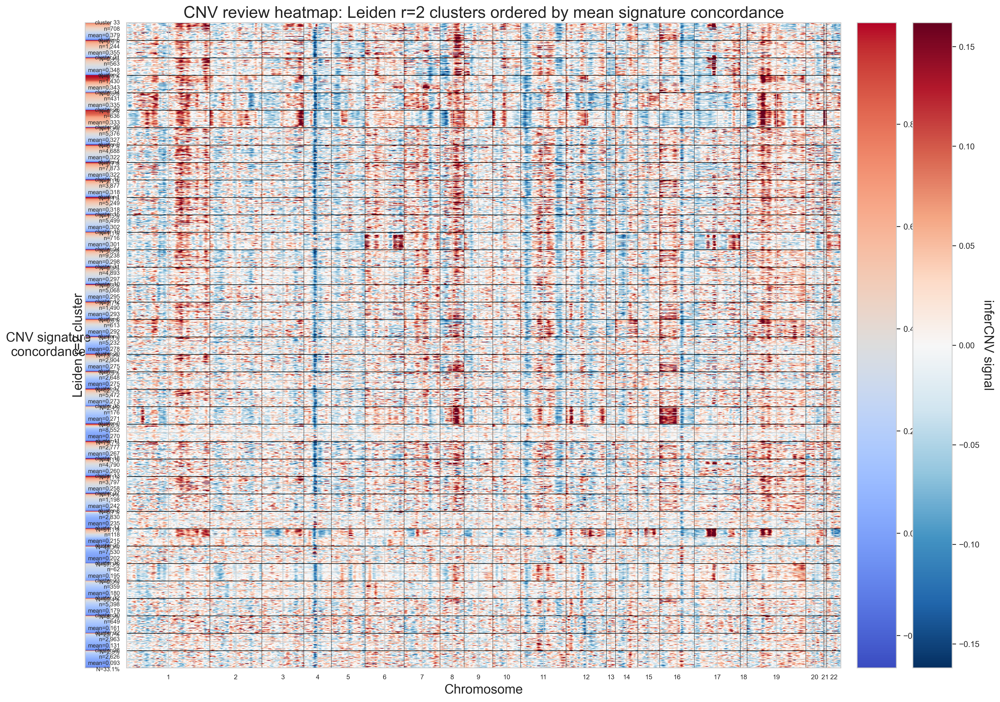

In [14]:
# ------------------------------------------------------------
# Cluster-level review heatmap
# ------------------------------------------------------------

review_meta = epi.obs[
    [
        MALIGNANCY_CLUSTER_KEY,
        "sample",
        "condition",
        "cnv_signature_score",
        "cnv_signature_support",
        "cnv_score",
        "cnv_forced_nonmalignant",
    ]
].copy()
review_meta["cluster"] = review_meta[
    MALIGNANCY_CLUSTER_KEY
].astype(str)

selected_parts = []
for cluster in cluster_order:
    group = review_meta[
        review_meta["cluster"].eq(cluster)
    ].sort_values(
        [
            "cnv_signature_score",
            "cnv_signature_support",
        ],
        ascending=[False, False],
        kind="mergesort",
    )
    if len(group) == 0:
        continue
    n_select = min(MAX_CELLS_PER_CLUSTER, len(group))
    positions = np.linspace(
        0,
        len(group) - 1,
        n_select,
    ).round().astype(int)
    selected_parts.append(group.iloc[positions])

cluster_plot_meta = pd.concat(selected_parts, axis=0)
cluster_plot_meta["_cluster_order"] = pd.Categorical(
    cluster_plot_meta["cluster"],
    categories=cluster_order,
    ordered=True,
)
cluster_plot_meta = cluster_plot_meta.sort_values(
    [
        "_cluster_order",
        "cnv_signature_score",
        "cnv_signature_support",
    ],
    ascending=[True, False, False],
    kind="mergesort",
)

cluster_plot_cells = cluster_plot_meta.index
cluster_row_idx = epi.obs_names.get_indexer(cluster_plot_cells)
cluster_matrix = X_cnv[cluster_row_idx]

cluster_plot_meta.assign(
    cell_id=lambda x: x.index.astype(str)
).to_csv(
    df_dir / "infercnv_leiden_r2_cluster_heatmap_cell_order.csv",
    index=False,
)

fig_height = max(
    10,
    min(18, 5 + 0.25 * len(cluster_order)),
)
fig = plt.figure(figsize=(19, fig_height))
gs = GridSpec(
    1,
    4,
    figure=fig,
    width_ratios=[0.35, 10.0, 0.55, 0.55],
    wspace=0.08,
)
score_ax = fig.add_subplot(gs[0, 0])
ax = fig.add_subplot(gs[0, 1])
score_cbar_ax = fig.add_subplot(gs[0, 2])
cnv_cbar_ax = fig.add_subplot(gs[0, 3])

all_scores = epi.obs["cnv_signature_score"].to_numpy(dtype=float)
all_scores = all_scores[np.isfinite(all_scores)]
score_norm = Normalize(
    vmin=float(np.min(all_scores)),
    vmax=float(np.max(all_scores)),
)

score_im = score_ax.imshow(
    cluster_plot_meta["cnv_signature_score"].to_numpy()[:, None],
    aspect="auto",
    cmap="coolwarm",
    norm=score_norm,
    interpolation="none",
)
score_ax.set_xticks([])
score_ax.set_yticks([])
score_ax.set_ylabel(
    "CNV signature\nconcordance",
    rotation=0,
    labelpad=45,
    va="center",
)

cluster_vmax = max(
    float(np.nanquantile(np.abs(cluster_matrix), 0.99)),
    1e-6,
)
cnv_im = ax.imshow(
    cluster_matrix,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-cluster_vmax,
    vmax=cluster_vmax,
    interpolation="none",
    rasterized=True,
)

for boundary in chr_boundaries[1:-1]:
    ax.axvline(boundary, color="black", linewidth=0.35)

values = cluster_plot_meta["cluster"].to_numpy()
changes = np.flatnonzero(values[1:] != values[:-1]) + 1
bounds = np.concatenate([[0], changes, [len(values)]])
centres = []
labels = []
summary_lookup = cluster_review_summary.set_index("cluster")

for start, end in zip(bounds[:-1], bounds[1:]):
    cluster = str(values[start])
    centres.append((start + end - 1) / 2)
    row = summary_lookup.loc[cluster]
    labels.append(
        f"cluster {cluster}\n"
        f"n={int(row['n_cells']):,}\n"
        f"mean={row['mean_signature_score']:.3f}\n"
        f"N={row['fraction_normal']:.1%}"
    )
    if start > 0:
        ax.axhline(start, color="black", linewidth=0.7)

ax.set_yticks(centres)
ax.set_yticklabels(labels, fontsize=7)
ax.set_xticks(chr_midpoints)
ax.set_xticklabels(
    [chromosome.replace("chr", "") for chromosome in chr_order],
    fontsize=8,
)
ax.set_xlabel("Chromosome")
ax.set_ylabel("Leiden r=2 cluster")
ax.set_title(
    "CNV review heatmap: Leiden r=2 clusters ordered by mean signature concordance"
)

fig.colorbar(score_im, cax=score_cbar_ax).set_label(
    "CNV signature concordance",
    rotation=270,
    labelpad=18,
)
fig.colorbar(cnv_im, cax=cnv_cbar_ax).set_label(
    "inferCNV signal",
    rotation=270,
    labelpad=18,
)

plt.savefig(
    fig_dir / "infercnv_leiden_r2_cluster_review.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


In [15]:
# ------------------------------------------------------------
# Final operational malignancy call
# ------------------------------------------------------------
# The signature score is not thresholded here. It orders the review heatmap.
# The final call is the explicit cluster-exclusion rule documented above.

epi.obs["malignant"] = (
    ~epi.obs["cnv_forced_nonmalignant"].astype(bool)
)
epi.obs["malignancy_review_pending"] = False
epi.obs["malignancy_status"] = np.where(
    epi.obs["malignant"],
    "Malignant_outside_reviewed_nonmalignant_groups",
    "Not_malignant_N_or_reviewed_r2_cluster",
)

epi.obs["malignancy_label"] = pd.Categorical(
    np.where(
        epi.obs["malignant"],
        "Malignant",
        "Non-malignant",
    ),
    categories=["Non-malignant", "Malignant"],
    ordered=True,
)
epi.uns["malignancy_label_colors"] = [
    "#BDBDBD",
    "#D73027",
]

# Update the metadata used by downstream notebooks.
epi.uns.setdefault("malignancy_call", {})
epi.uns["malignancy_call"].update(
    {
        "primary_call": "resolution_2_cluster_exclusion_review",
        "status": "complete",
        "review_cluster_key": MALIGNANCY_CLUSTER_KEY,
        "manual_nonmalignant_r2_clusters": sorted(
            MANUAL_NONMALIGNANT_R2_CLUSTERS
        ),
        "normal_dominant_r2_clusters": sorted(
            normal_dominant_r2_clusters
        ),
        "normal_dominance_fraction": float(
            NORMAL_DOMINANCE_FRACTION
        ),
        "cnv_signature_used_for_ordering": True,
        "cnv_signature_used_as_final_threshold": False,
        "cnv_score_used_for_final_call": False,
    }
)

print(
    "Malignant cells:",
    int(epi.obs["malignant"].sum()),
)
print(
    "Non-malignant cells:",
    int((~epi.obs["malignant"]).sum()),
)
display(
    pd.crosstab(
        epi.obs["condition"].astype(str),
        epi.obs["malignancy_label"],
        margins=True,
    )
)


Malignant cells: 89428
Non-malignant cells: 30245


malignancy_label,Non-malignant,Malignant,All
condition,,,
ER+,1776,56076,57852
HER2+,1046,15478,16524
N,25682,0,25682
TN,1741,17874,19615
All,30245,89428,119673


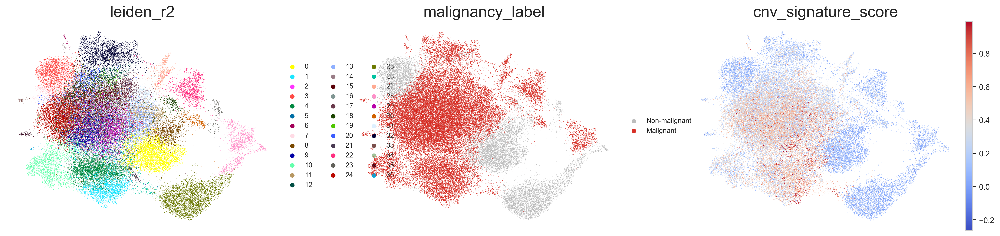

In [16]:
# ------------------------------------------------------------
# UMAPs: resolution-2 clusters, malignancy call and signature score
# ------------------------------------------------------------

sc.pl.umap(
    epi,
    color=[
        MALIGNANCY_CLUSTER_KEY,
        "malignancy_label",
        "cnv_signature_score",
    ],
    ncols=3,
    cmap="coolwarm",
    vmax="p99.9",
    frameon=False,
    show=False,
)
plt.savefig(
    fig_dir / "epithelial_umap_r2_malignancy_signature.svg",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()


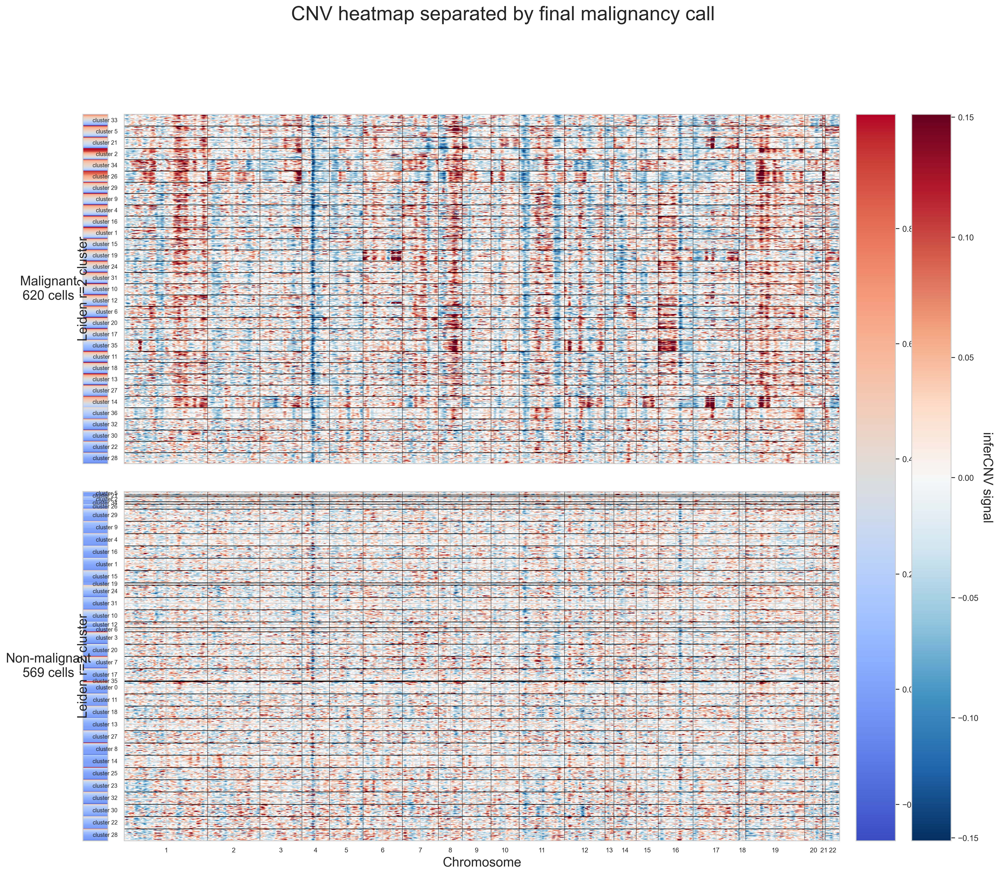

In [17]:
# ------------------------------------------------------------
# Heatmap split by the final malignant/non-malignant call
# ------------------------------------------------------------

MAX_CELLS_PER_CLUSTER_AND_GROUP = 20
split_meta = epi.obs[
    [
        MALIGNANCY_CLUSTER_KEY,
        "sample",
        "condition",
        "cnv_signature_score",
        "cnv_signature_support",
        "cnv_score",
        "malignant",
        "malignancy_label",
    ]
].copy()
split_meta["cluster"] = split_meta[
    MALIGNANCY_CLUSTER_KEY
].astype(str)

selected_parts = []
for label in ["Malignant", "Non-malignant"]:
    for cluster in cluster_order:
        group = split_meta[
            split_meta["malignancy_label"].eq(label)
            & split_meta["cluster"].eq(cluster)
        ].sort_values(
            ["cnv_signature_score", "cnv_signature_support"],
            ascending=[False, False],
            kind="mergesort",
        )
        if len(group) == 0:
            continue
        n_select = min(
            MAX_CELLS_PER_CLUSTER_AND_GROUP,
            len(group),
        )
        positions = np.linspace(
            0,
            len(group) - 1,
            n_select,
        ).round().astype(int)
        selected_parts.append(group.iloc[positions])

split_plot = pd.concat(selected_parts, axis=0)
split_plot["_label_order"] = pd.Categorical(
    split_plot["malignancy_label"],
    categories=["Malignant", "Non-malignant"],
    ordered=True,
)
split_plot["_cluster_order"] = pd.Categorical(
    split_plot["cluster"],
    categories=cluster_order,
    ordered=True,
)
split_plot = split_plot.sort_values(
    [
        "_label_order",
        "_cluster_order",
        "cnv_signature_score",
        "cnv_signature_support",
    ],
    ascending=[True, True, False, False],
    kind="mergesort",
)

split_cells = split_plot.index
split_row_idx = epi.obs_names.get_indexer(split_cells)
split_matrix = X_cnv[split_row_idx]

split_plot.assign(
    cell_id=lambda x: x.index.astype(str)
).to_csv(
    df_dir / "infercnv_malignant_vs_nonmalignant_r2_heatmap_cell_order.csv",
    index=False,
)

fig = plt.figure(figsize=(19, 16))
gs = GridSpec(
    2,
    4,
    figure=fig,
    width_ratios=[0.35, 10.0, 0.55, 0.55],
    height_ratios=[1, 1],
    hspace=0.08,
    wspace=0.08,
)
score_axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])]
heatmap_axes = [fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])]
score_cbar_ax = fig.add_subplot(gs[:, 2])
cnv_cbar_ax = fig.add_subplot(gs[:, 3])

all_scores = epi.obs["cnv_signature_score"].to_numpy(dtype=float)
all_scores = all_scores[np.isfinite(all_scores)]
score_norm = Normalize(
    vmin=float(np.min(all_scores)),
    vmax=float(np.max(all_scores)),
)
heatmap_vmax = max(
    float(np.nanquantile(np.abs(split_matrix), 0.99)),
    1e-6,
)

score_im = None
cnv_im = None
for row, label in enumerate(["Malignant", "Non-malignant"]):
    mask = split_plot["malignancy_label"].eq(label).to_numpy()
    matrix = split_matrix[mask]
    scores = split_plot.loc[mask, "cnv_signature_score"].to_numpy()
    score_ax = score_axes[row]
    ax = heatmap_axes[row]

    score_im = score_ax.imshow(
        scores[:, None],
        aspect="auto",
        cmap="coolwarm",
        norm=score_norm,
        interpolation="none",
    )
    score_ax.set_xticks([])
    score_ax.set_yticks([])
    score_ax.set_ylabel(
        f"{label}\n{len(scores):,} cells",
        rotation=0,
        labelpad=42,
        va="center",
    )

    cnv_im = ax.imshow(
        matrix,
        aspect="auto",
        cmap="RdBu_r",
        vmin=-heatmap_vmax,
        vmax=heatmap_vmax,
        interpolation="none",
        rasterized=True,
    )
    for boundary in chr_boundaries[1:-1]:
        ax.axvline(boundary, color="black", linewidth=0.35)

    values = split_plot.loc[mask, "cluster"].to_numpy()
    changes = np.flatnonzero(values[1:] != values[:-1]) + 1
    bounds = np.concatenate([[0], changes, [len(values)]])
    centres = []
    labels = []
    for start, end in zip(bounds[:-1], bounds[1:]):
        centres.append((start + end - 1) / 2)
        labels.append(f"cluster {values[start]}")
        if start > 0:
            ax.axhline(start, color="black", linewidth=0.7)
    ax.set_yticks(centres)
    ax.set_yticklabels(labels, fontsize=7)
    if row == 1:
        ax.set_xticks(chr_midpoints)
        ax.set_xticklabels(
            [chromosome.replace("chr", "") for chromosome in chr_order],
            fontsize=8,
        )
        ax.set_xlabel("Chromosome")
    else:
        ax.set_xticks([])
    ax.set_ylabel("Leiden r=2 cluster")

fig.colorbar(score_im, cax=score_cbar_ax).set_label(
    "CNV signature concordance",
    rotation=270,
    labelpad=18,
)
fig.colorbar(cnv_im, cax=cnv_cbar_ax).set_label(
    "inferCNV signal",
    rotation=270,
    labelpad=18,
)
fig.suptitle(
    "CNV heatmap separated by final malignancy call",
    y=0.995,
)
plt.savefig(
    fig_dir / "infercnv_malignant_vs_nonmalignant_r2.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


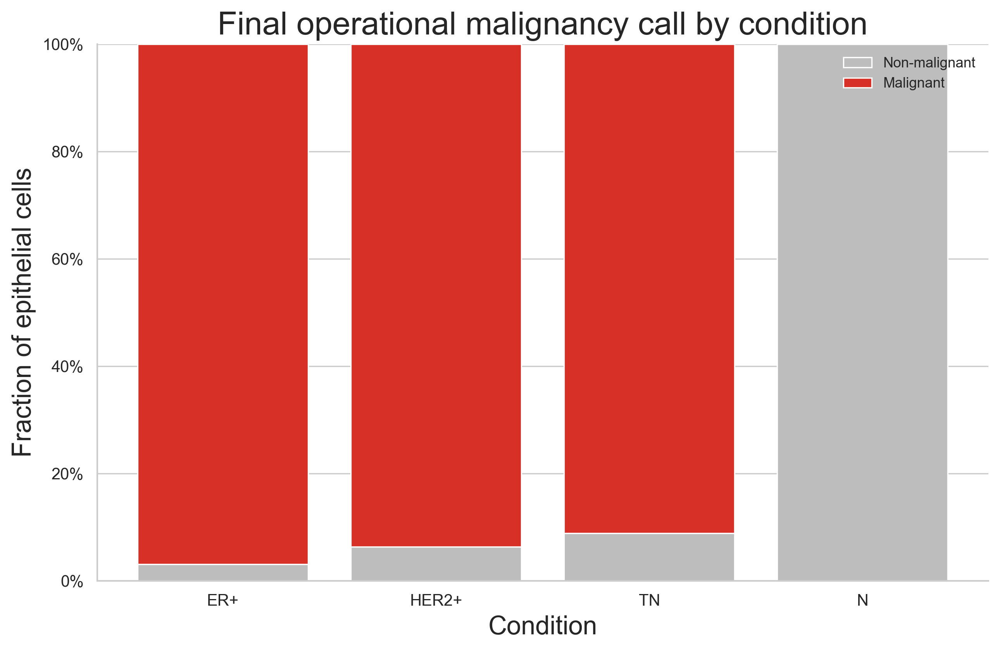

In [18]:
# ------------------------------------------------------------
# Stacked cell fraction by condition
# ------------------------------------------------------------

condition_order_for_plot = [
    condition
    for condition in ["ER+", "HER2+", "TN", "N"]
    if condition in epi.obs["condition"].astype(str).unique()
]

counts = pd.crosstab(
    epi.obs["condition"].astype(str),
    epi.obs["malignancy_label"],
).reindex(
    index=condition_order_for_plot,
    columns=["Non-malignant", "Malignant"],
    fill_value=0,
)
proportions = counts.div(counts.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 6))
x = np.arange(len(proportions))
nonmalignant = proportions["Non-malignant"].to_numpy()
malignant = proportions["Malignant"].to_numpy()

ax.bar(x, nonmalignant, color="#BDBDBD", label="Non-malignant")
ax.bar(
    x,
    malignant,
    bottom=nonmalignant,
    color="#D73027",
    label="Malignant",
)

ax.set_xticks(x)
ax.set_xticklabels(proportions.index)
ax.set_ylim(0, 1)
ax.set_ylabel("Fraction of epithelial cells")
ax.set_xlabel("Condition")
ax.set_title("Final operational malignancy call by condition")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, position: f"{value:.0%}")
)
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.savefig(
    fig_dir / "malignant_fraction_by_condition_stacked.png",
    dpi=300,
    bbox_inches="tight",
)
proportions.to_csv(
    df_dir / "malignant_fraction_by_condition.csv"
)
plt.show()
plt.close(fig)


### Interpretation of the operational call

The final `malignant` field is a review-based operational label. It is not inferred from `cnv_score`, and it is not a validated pathological ground truth. The CNV-signature score determines the review order and supports visual inspection. The final exclusion rules are explicit: all normal-condition cells, all normal-dominated resolution-2 clusters, and the manually reviewed non-malignant resolution-2 clusters are non-malignant; all remaining cells are labelled malignant. Any downstream biological comparison should be repeated at sample/donor level.


In [19]:
from sklearn.metrics import silhouette_score

In [20]:
rng = np.random.default_rng(0)

n_eval = min(20000, epi.n_obs)
eval_idx = rng.choice(epi.n_obs, size=n_eval, replace=False)

z_eval = epi.obsm["X_scVI"][eval_idx]
obs_eval = epi.obs.iloc[eval_idx]

bio_asw = silhouette_score(z_eval, obs_eval["cl_annotation"], metric="euclidean")
batch_asw = silhouette_score(z_eval, obs_eval["sample"], metric="euclidean")

print(f"annotation silhouette: {bio_asw:.3f}")
print(f"sample silhouette:     {batch_asw:.3f}")

annotation silhouette: 0.033
sample silhouette:     -0.089


In [21]:

pd.DataFrame({
    "metric": ["annotation_silhouette", "sample_silhouette"],
    "value": [bio_asw, batch_asw],
}).to_csv(df_dir / "scvi_epithelial_integration_metrics.csv", index=False)

In [22]:
# a cluster dominated by one sample is a candidate residual batch effect
sample_counts = pd.crosstab(epi.obs["epi_leiden"], epi.obs["sample"])
sample_fractions = sample_counts.div(sample_counts.sum(axis=1), axis=0)

p = sample_fractions.replace(0, np.nan)

cluster_composition = pd.DataFrame({
    "n_cells": sample_counts.sum(axis=1),
    "n_samples": (sample_counts > 0).sum(axis=1),
    "top_sample": sample_fractions.idxmax(axis=1),
    "top_sample_fraction": sample_fractions.max(axis=1),
    "sample_entropy": -(p * np.log(p)).sum(axis=1) / np.log(sample_fractions.shape[1]),
})

print(cluster_composition.sort_values("top_sample_fraction", ascending=False).round(3).to_string())

            n_cells  n_samples                 top_sample  top_sample_fraction  sample_entropy
epi_leiden                                                                                    
12               58          2     GSM4909293_HER2-MH0161                0.983           0.023
23              166          4    GSM4909306_ER-MH0029-9C                0.970           0.043
6                60          6    GSM4909305_ER-MH0029-7C                0.900           0.127
2               547         14     GSM4909289_HER2-AH0308                0.890           0.155
25             1167         36   GSM4909287_TN-B1-Tum0554                0.632           0.438
24              386         17  GSM4909257_N-PM0095-Total                0.469           0.488
16             5005         44     GSM4909294_HER2-MH0176                0.321           0.600
18             8000         32  GSM4909270_N-PM0342-Total                0.308           0.561
11             6544         42    GSM4909299_ER-MH

In [23]:
cluster_composition.to_csv(df_dir / "scvi_epithelial_cluster_sample_composition.csv")

In [24]:
# canonical epithelial markers, to confirm the clusters are epithelial
marker_genes = [
    g for g in ["EPCAM", "KRT8", "KRT18", "KRT19", "KRT7", "KRT5", "KRT14", "KRT17", "MUC1"]
    if g in epi.var_names
]

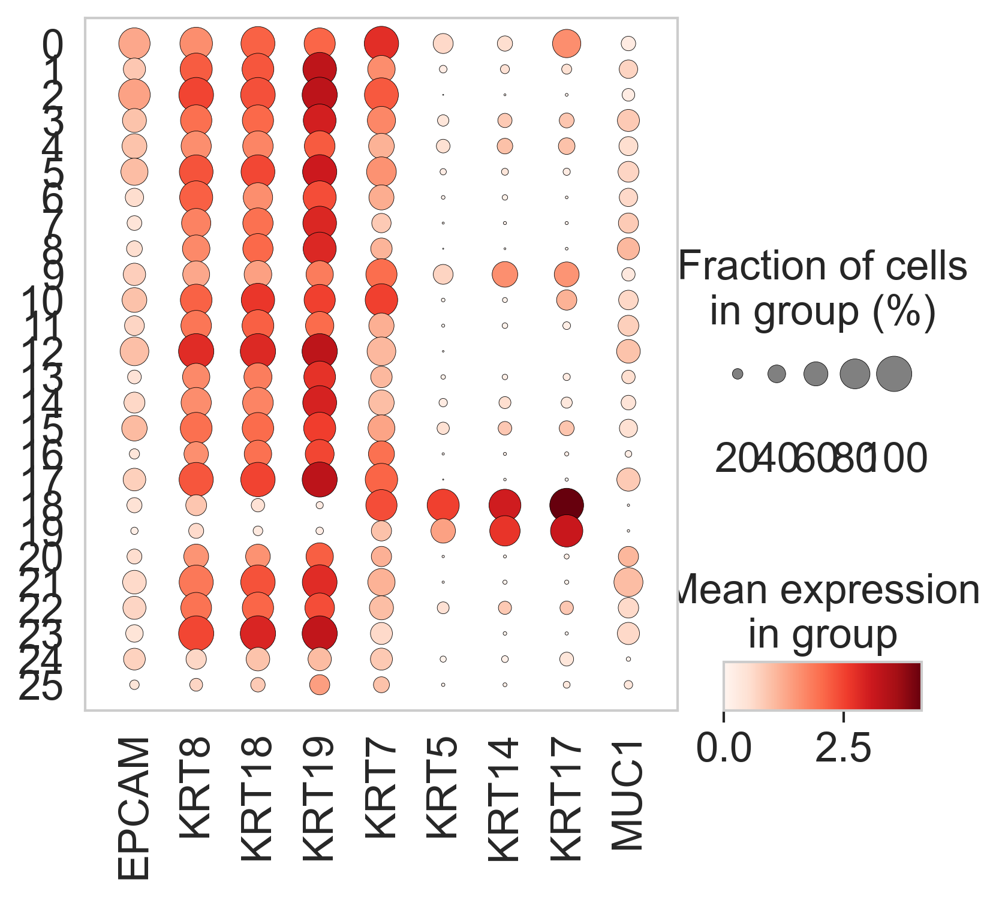

In [25]:
sc.pl.dotplot(epi,
    var_names=marker_genes, groupby="epi_leiden", layer="lognorm", use_raw=False, figsize=(6, 5), show=False)
plt.savefig(fig_dir / "epithelial_cluster_markers_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

## Figure 1a and related UMAPs

In [26]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}

condition_order = ["TN", "HER2+", "ER+", "N"]

epi.obs["condition"] = pd.Categorical(
    epi.obs["condition"].astype(str), categories=condition_order, ordered=True
)

In [27]:

# set the colours on the object, so plotting a subset does not have to write them
epi.uns["condition_colors"] = [condition_palette[c] for c in condition_order]

In [28]:

epi.obs["cl_annotation"] = epi.obs["cl_annotation"].astype("category")

In [29]:

epi.obs["sample_short"] = (
    epi.obs["sample_short"].astype("category").cat.remove_unused_categories()
)

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


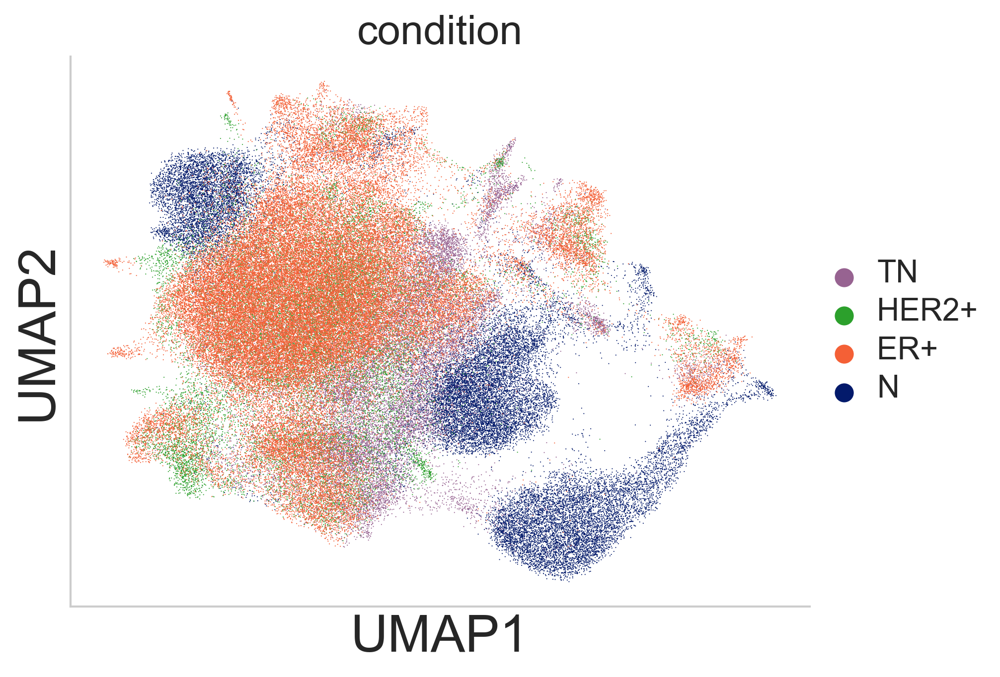

In [30]:
# draw N first so that the tumour conditions are not hidden underneath it
draw_order = ["N", "TN", "HER2+", "ER+"]
rank = {condition: i for i, condition in enumerate(draw_order)}

plot_idx = epi.obs["condition"].astype(str).map(rank).sort_values().index

sc.pl.umap(epi[plot_idx], color="condition", palette=condition_palette, frameon=True, show=False)

ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)
ax.tick_params(axis="both", labelsize=12)

legend = ax.get_legend()

if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])

plt.savefig(fig_dir / "epithelial_umap_condition.png", dpi=300, bbox_inches="tight")
plt.show()

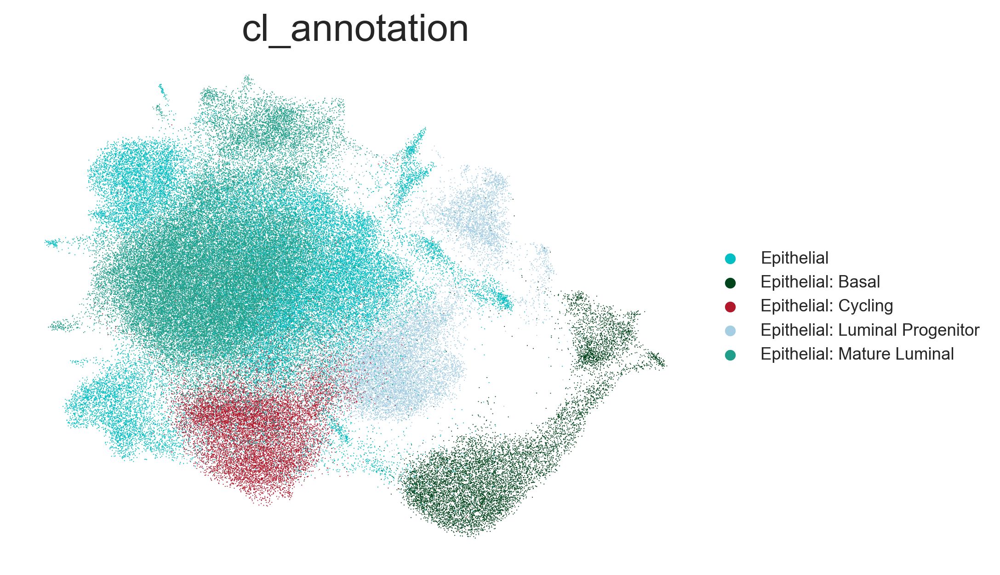

In [31]:
sc.pl.umap(epi, color="cl_annotation", frameon=False, show=False)

plt.savefig(fig_dir / "epithelial_umap_cl_annotation.png", dpi=300, bbox_inches="tight")
plt.show()

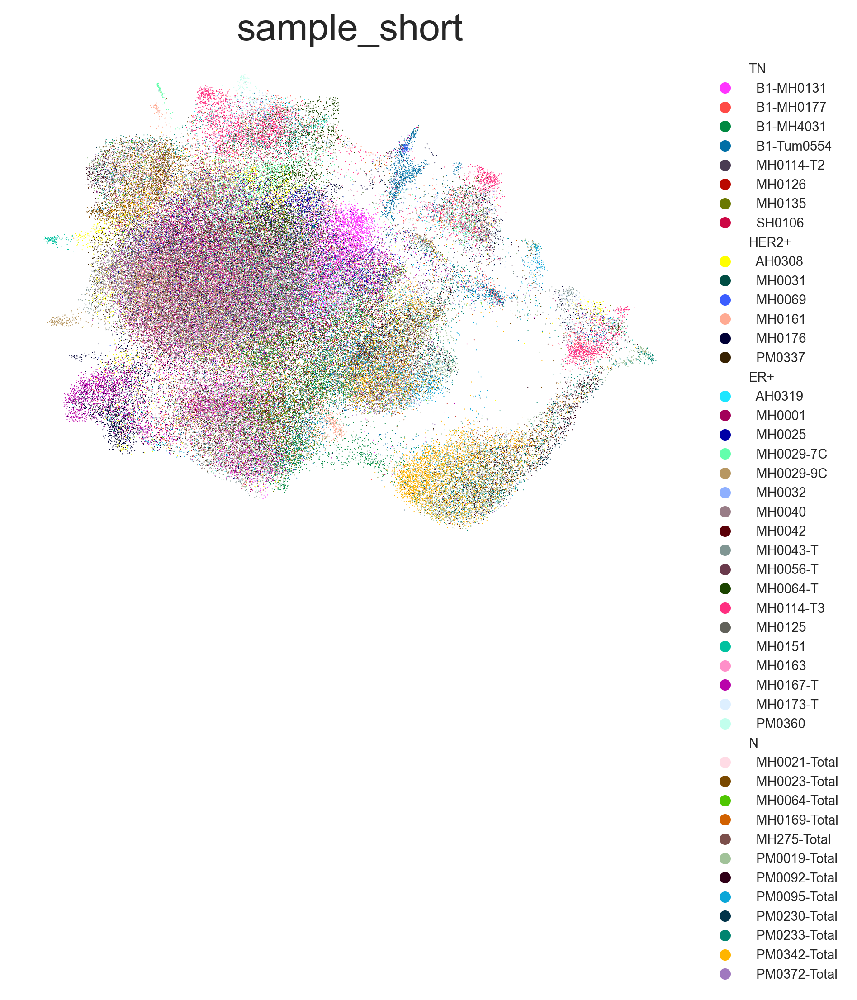

In [32]:
# samples coloured individually, with the legend grouped by condition
sc.pl.umap(epi, color="sample_short", legend_loc=None, frameon=False, show=False)

ax = plt.gca()

# read the colours scanpy just assigned, so the legend matches the plot
sample_to_color = dict(
    zip(epi.obs["sample_short"].cat.categories, epi.uns["sample_short_colors"])
)

handles = []

for condition in condition_order:

    handles.append(Line2D([], [], linestyle="none", label=condition, color="black"))
    for sample in sorted(epi.obs.loc[epi.obs["condition"] == condition, "sample_short"].unique()):
        handles.append(
            Line2D([], [], marker="o", linestyle="none", markersize=6, markerfacecolor=sample_to_color[sample], markeredgecolor="none", label=f"  {sample}")
        )

ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=7)

plt.savefig(fig_dir / "epithelial_umap_sample.png", dpi=300, bbox_inches="tight")
plt.show()

In [33]:
chr_pos = cnv_full.uns["cnv"]["chr_pos"]  # chromosome -> start column index in X_cnv
chr_order = sorted(chr_pos, key=lambda c: chr_pos[c])
chr_boundaries = [chr_pos[c] for c in chr_order] + [X_cnv.shape[1]]
chr_midpoints = [(chr_boundaries[i] + chr_boundaries[i + 1]) / 2 for i in range(len(chr_order))]

vmax = float(np.nanquantile(np.abs(X_cnv), 0.99))

In [34]:
complexity_by_cluster = (
    epi.obs.groupby("epi_leiden", observed=True)
    .agg(n_cells=("malignant", "size"),
         n_malignant=("malignant", "sum"),
         malignant_fraction=("malignant", "mean"),
         median_cnv=("cnv_score", "median"),
         median_n_genes=("n_genes_by_counts", "median"),
         median_top20=("pct_counts_in_top_20_genes", "median"))
    .sort_values("malignant_fraction")
)
print(complexity_by_cluster.round(3))

# These are cell-level diagnostics only. A correlation does not prove that
# transcriptomic complexity causes CNV-score bias; sample-level replication is
# needed before making such a claim.
tumour_mask = epi.obs["condition"].ne("N")
for col in ["n_genes_by_counts", "total_counts", "pct_counts_in_top_20_genes"]:
    valid = tumour_mask & epi.obs["cnv_score"].notna() & epi.obs[col].notna()
    r = np.corrcoef(epi.obs.loc[valid, "cnv_score"], epi.obs.loc[valid, col])[0, 1]
    print(f"cell-level CNV score vs {col}: r = {r:.3f}")


            n_cells  n_malignant  malignant_fraction  median_cnv  \
epi_leiden                                                         
24              386           11               0.028       0.039   
0             11110          400               0.036       0.034   
18             8000          342               0.043       0.043   
10             7650          383               0.050       0.045   
19             2486         1756               0.706       0.045   
5              1259         1018               0.809       0.054   
20             4585         4086               0.891       0.052   
13             7910         7321               0.926       0.050   
11             6544         6071               0.928       0.047   
25             1167         1094               0.937       0.047   
4              9698         9257               0.955       0.056   
6                60           58               0.967       0.058   
9              2954         2861               0

The complexity correlations above are descriptive cell-level diagnostics. They do not establish causality, and cells should not be treated as independent biological replicates for condition-level inference.


## Robustness appendix — does the protected gene list shape the latent space?



The Methods require the target and Gavish signature genes to be added to the
integration feature set, and they make up a substantial minority of it. A
reviewer can reasonably ask whether the latent structure was partly engineered
towards the biology analysed afterwards.

This appendix trains a second scVI model on the **4,000 deviance-ranked genes
only** and compares the two representations. inferCNV and the malignancy call
are not repeated: neither depends on the integration feature set. Neither are
the Gavish states in 003b, which are scored on the full expression matrix, nor
the antigen calls in 003c, which are raw counts. The only result that depends
on Leiden is the Figure 1d bubble plot, so `epi_leiden_deviance` is stored for
that sensitivity check.

UMAP appearance is deliberately not the comparison: embeddings can rotate and
rearrange while the underlying neighbourhoods are unchanged.
Two scVI models never agree exactly, even on identical input, so a
feature-set comparison is uninterpretable on its own. A third model is
therefore trained on the **same protected gene set with a different seed**,
to establish the run-to-run floor. The feature-set effect is only real if it
exceeds that floor.


In [ ]:
epi_deviance = epi[:, epi.var["highly_variable_deviance"]].copy()

In [ ]:

assert epi_deviance.n_vars == n_hvg_deviance

In [ ]:

scvi.model.SCVI.setup_anndata(epi_deviance, layer="counts", batch_key="sample")

In [ ]:

model_deviance = scvi.model.SCVI(epi_deviance, n_latent=20, n_layers=2, gene_likelihood='nb')

In [ ]:
model_deviance.train(
    max_epochs=400, accelerator="mps", batch_size=1024,
    early_stopping=True, early_stopping_patience=20,
    early_stopping_min_delta=SCVI_EARLY_STOPPING_MIN_DELTA,
)


In [ ]:

model_deviance.history['elbo_train'].shape[0]

In [ ]:
epi.obsm["X_scVI_deviance"] = model_deviance.get_latent_representation()

In [ ]:
# free the large intermediates; nothing below uses them
del model_deviance
gc.collect()

In [ ]:
sc.pp.neighbors(
    epi, use_rep="X_scVI_deviance", n_neighbors=30, random_state=RANDOM_SEED,
    key_added="deviance_neighbors",
)
sc.tl.leiden(
    epi, resolution=PRIMARY_LEIDEN_RESOLUTION, key_added="epi_leiden_deviance",
    neighbors_key="deviance_neighbors", flavor="igraph", n_iterations=2,
    directed=False, random_state=RANDOM_SEED,
)
del epi_deviance
gc.collect()


In [ ]:
# run-to-run floor: same genes as the primary model, different seed
epi_seed = epi[:, epi.var["highly_variable"]].copy()
scvi.settings.seed = RANDOM_SEED + 1
scvi.model.SCVI.setup_anndata(epi_seed, layer="counts", batch_key="sample")
model_seed = scvi.model.SCVI(epi_seed, n_latent=20, n_layers=2, gene_likelihood="nb")
model_seed.train(
    max_epochs=400, accelerator="mps", batch_size=1024,
    early_stopping=True, early_stopping_patience=20,
    early_stopping_min_delta=SCVI_EARLY_STOPPING_MIN_DELTA,
)
epi.obsm["X_scVI_seed2"] = model_seed.get_latent_representation()
scvi.settings.seed = RANDOM_SEED
sc.pp.neighbors(epi, use_rep="X_scVI_seed2", n_neighbors=30, random_state=RANDOM_SEED, key_added="seed2_neighbors")
sc.tl.leiden(
    epi, resolution=PRIMARY_LEIDEN_RESOLUTION, key_added="epi_leiden_seed2",
    neighbors_key="seed2_neighbors", flavor="igraph", n_iterations=2,
    directed=False, random_state=RANDOM_SEED,
)
del epi_seed
gc.collect()


In [ ]:
# free the large intermediates; nothing below uses them
del model_seed
gc.collect()

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors

k_overlap = 30
overlap_idx = eval_idx          # the same subsample used for the silhouettes


def knn_indices(representation):
    z = epi.obsm[representation][overlap_idx]
    nn = NearestNeighbors(n_neighbors=k_overlap + 1).fit(z)
    return nn.kneighbors(z, return_distance=False)[:, 1:]


nn_primary = knn_indices("X_scVI")

rows = []

for label, representation, clustering in [
    ("feature set (deviance-only)", "X_scVI_deviance", "epi_leiden_deviance"),
    ("seed only (run-to-run floor)", "X_scVI_seed2", "epi_leiden_seed2"),
]:

    nn_other = knn_indices(representation)

    overlap = np.array([
        len(set(a) & set(b)) / k_overlap for a, b in zip(nn_primary, nn_other)
    ])

    rows.append({
        "comparison_against_primary": label,
        "leiden_ari": adjusted_rand_score(epi.obs["epi_leiden"], epi.obs[clustering]),
        "leiden_nmi": normalized_mutual_info_score(epi.obs["epi_leiden"], epi.obs[clustering]),
        "knn_overlap_mean": overlap.mean(),
        "knn_overlap_median": float(np.median(overlap)),
        "n_clusters": int(epi.obs[clustering].nunique()),
    })

latent_comparison = pd.DataFrame(rows)

print(f"primary model: {int(epi.obs['epi_leiden'].nunique())} clusters\n")
print(latent_comparison.round(3).to_string(index=False))

print(
    "\nthe feature-set effect is only meaningful where it exceeds the seed-only floor"
)

latent_comparison.to_csv(df_dir / "scvi_latent_comparison.csv", index=False)

In [ ]:
# batch and biology separation in all three representations
rows = []

for label, representation in [
    ("protected (primary)", "X_scVI"),
    ("deviance_only", "X_scVI_deviance"),
    ("protected, seed 2", "X_scVI_seed2"),
]:

    z = epi.obsm[representation][eval_idx]

    rows.append({
        "model": label,
        "annotation_silhouette": silhouette_score(z, obs_eval["cl_annotation"]),
        "sample_silhouette": silhouette_score(z, obs_eval["sample"]),
        "condition_silhouette": silhouette_score(z, obs_eval["condition"].astype(str)),
    })

model_comparison = pd.DataFrame(rows)

print(model_comparison.round(3).to_string(index=False))

In [ ]:
# free the large intermediates; nothing below uses them
del model
gc.collect()

In [ ]:
# batch mixing measured within each annotation, so that biological separation is not mistaken for good mixing
rows = []

for annotation in obs_eval["cl_annotation"].value_counts().index:

    mask = (obs_eval["cl_annotation"] == annotation).to_numpy()

    if mask.sum() < 100 or obs_eval.loc[mask, "sample"].nunique() < 2:
        continue

    row = {"cl_annotation": annotation, "n_cells": int(mask.sum())}

    for label, representation in [
        ("protected", "X_scVI"),
        ("deviance_only", "X_scVI_deviance"),
        ("seed2", "X_scVI_seed2"),
    ]:
        row[label] = silhouette_score(
            epi.obsm[representation][eval_idx][mask], obs_eval.loc[mask, "sample"]
        )

    rows.append(row)

within_annotation = pd.DataFrame(rows)

print(within_annotation.round(3).to_string(index=False))

In [ ]:
annotation_agreement = pd.crosstab(epi.obs["epi_leiden"], epi.obs["epi_leiden_deviance"])
best_match = annotation_agreement.max(axis=1) / annotation_agreement.sum(axis=1)

print("fraction of each primary cluster falling in a single deviance-only cluster")
print(best_match.round(3).sort_values().to_string())

feature_effect = latent_comparison.iloc[0]
seed_floor = latent_comparison.iloc[1]

epi.uns["protected_gene_sensitivity"] = {
    "question": "does adding target and Gavish genes to the scVI feature set "
                "change the epithelial latent structure beyond run-to-run variation",
    "primary_features": int(n_hvg),
    "deviance_only_features": int(n_hvg_deviance),
    "protected_added": int(n_protected_added),
    "protected_fraction": float(n_protected_added / n_hvg),
    "feature_set_ari": float(feature_effect["leiden_ari"]),
    "seed_floor_ari": float(seed_floor["leiden_ari"]),
    "feature_set_knn_overlap": float(feature_effect["knn_overlap_mean"]),
    "seed_floor_knn_overlap": float(seed_floor["knn_overlap_mean"]),
    "k": int(k_overlap),
}

model_comparison.to_csv(df_dir / "scvi_protected_gene_sensitivity.csv", index=False)
within_annotation.to_csv(df_dir / "scvi_protected_gene_sensitivity_by_annotation.csv", index=False)
best_match.rename("largest_matching_fraction").to_csv(df_dir / "scvi_protected_gene_cluster_correspondence.csv")

## Save

In [36]:
# Nothing in this notebook may alter the raw counts.
final_counts = epi.layers["counts"]
assert sp.issparse(final_counts)
assert np.equal(final_counts.data, np.floor(final_counts.data)).all()
final_positive = {
    g: int(final_counts[:, epi.var_names.get_loc(g)].count_nonzero())
    if g in epi.var_names else 0
    for g in target_genes
}
if epi.obs["malignancy_review_pending"].any():
    raise RuntimeError("Resolution-2 cluster review is still pending. Run the final cluster-exclusion malignancy call before saving the final object.")

assert epi.n_obs == n_cells_start
assert epi.n_vars == n_genes_start
assert final_positive == {g: baseline_positive[g] for g in final_positive}
assert int(epi.obs.groupby("sample", observed=True).size().max()) <= MAX_CELLS_PER_SAMPLE
assert epi.obs["malignant"].dtype == bool
print(epi)


AnnData object with n_obs × n_vars = 119673 × 27274
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class', 'batch', 'patient', 'sample_short', 'celltypist_pal_label', 'celltypist_pal_conf', 'cl_annotation', 'cnv_score', 'cnv_signal', 'cnv_high_screen', 'malignant', 'malignancy_review_pending', 'malignancy_status', 'leiden_r0.2', 'leiden_r0.4', 'leiden_r0.6', 'leiden_r0.8', 'leiden_r1', 'leiden_r1.2', 'leiden_r1.5', 'leiden_r2', 'epi_leiden', 'cnv_forced_nonmalignant', 'cnv_signature_score', 'cnv_signature_support', 'malignancy_label'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells', 'binomial_deviance', 'highly_variable_devian

In [39]:
epi.uns["epithelial_integration"] = {
    "hvg_method": "binomial deviance (scry), max across samples",
    "n_hvg_deviance": int(4000),
    "n_hvg_total": int(n_hvg),
    "protected_genes": "ROR1, EGFR, ERBB2, EPCAM, ROR2 and Gavish cancer meta-programme genes",
    "sample_cap_max_cells": int(MAX_CELLS_PER_SAMPLE),
    "sample_cap_sampling": "deterministic within-sample stratified sampling by cl_annotation when available",
    "cnv_heatmap_max_cells": int(HEATMAP_MAX_CELLS),
    "cnv_primary_call": "manual visual review threshold; diagnostic normal quantile is not primary",
    "cnv_gene_exclusion_sensitivity_required": True,
    "scvi_n_latent": int(20), "scvi_n_layers": int(2),
    "scvi_gene_likelihood": "nb", "scvi_batch_key": "sample",
    "scvi_epochs": int(n_epochs), "scvi_early_stopping_min_delta": float(SCVI_EARLY_STOPPING_MIN_DELTA),
    "n_neighbors": int(30),
    "leiden_resolutions": [float(x) for x in leiden_resolutions],
    #"leiden_primary": float(primary_resolution),
    "seed": int(RANDOM_SEED),
}


In [40]:
out_path = save_dir / "epithelial_malignancy_scvi.h5ad"

for name in list(epi.layers.keys()):
    if not sp.issparse(epi.layers[name]):
        epi.layers[name] = sp.csr_matrix(epi.layers[name])

if not sp.issparse(epi.X):
    epi.X = sp.csr_matrix(epi.X)

# write to a temporary file first, so an interrupted write cannot destroy the object
tmp_path = out_path.with_suffix(".h5ad.tmp")

epi.write_h5ad(tmp_path, compression="gzip")
os.replace(tmp_path, out_path)

print(out_path.name)

epithelial_malignancy_scvi.h5ad


In [41]:
check = sc.read_h5ad(out_path, backed="r")

assert check.n_obs == epi.n_obs
assert check.n_vars == epi.n_vars

check.shape

(119673, 27274)

In [42]:

del check
gc.collect()

1484

In [43]:
# session_info.show() has exhausted the kernel on the larger objects in this project, so the versions that matter are recorded directly
import sys
from importlib.metadata import version, PackageNotFoundError

packages = [
    "scanpy", "anndata", "scvi-tools", "numpy", "pandas", "scipy", "scikit-learn",
    "matplotlib", "seaborn", "statsmodels", "infercnvpy", "leidenalg", "igraph",
    "rpy2", "papermill", "session-info",
]

versions = {"python": sys.version.split()[0]}

for name in packages:
    try:
        versions[name] = version(name)
    except PackageNotFoundError:
        continue

pd.Series(versions, name="version").to_frame()

,version
python,3.11.15
scanpy,1.11.5
anndata,0.12.11
scvi-tools,1.4.2
numpy,2.4.4
pandas,2.3.3
scipy,1.17.1
scikit-learn,1.8.0
matplotlib,3.10.9
seaborn,0.13.2
